# Auditoría del conjunto de entrenamiento de PosFormer

Este notebook audita el conjunto de entrenamiento ubicado en `data/Modelo2/train`.

## Objetivos

- Verificar la correspondencia entre anotaciones, imágenes `.bmp` y archivos `.lg`.
- Describir dimensiones, modos y contenido visual aproximado de las imágenes.
- Auditar las secuencias LaTeX, sus tokens y convenciones de escritura, con atención especial a `\\limits`.
- Identificar referencias repetidas y distinguirlas de imágenes exactamente duplicadas.
- Buscar coincidencias exactas de identificadores o imágenes con el test CROHME 2014 de PosFormer.
- Generar tablas reproducibles para revisar manualmente los hallazgos.

## Límites metodológicos

Este análisis es descriptivo. No entrena ni modifica modelos, imágenes o anotaciones; tampoco convierte automáticamente ninguna observación en una regla de normalización. La eventual normalización de LaTeX debe ser conservadora, aplicarse solo en la comparación y preservar el significado matemático y la estructura. CROHME 2016 y 2019 no se inspeccionan aquí.

CROHME 2014 se utiliza únicamente para auditar posibles coincidencias y diferencias de convención con el conjunto de desarrollo del proyecto. La coincidencia de una referencia LaTeX por sí sola no implica fuga de datos; una imagen idéntica sí requiere revisión.

## 1. Configuración e importaciones

La semilla solo controla la selección reproducible de ejemplos visuales. El umbral de trazo se usa para una descripción aproximada de píxeles que difieren del fondo y no representa una medida física de tinta.

In [1]:
# Librerías estándar para rutas, expresiones regulares, conteos y huellas digitales.
from pathlib import Path
from collections import Counter
import hashlib
import json
import re

# Librerías para tablas, imágenes y visualización.
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Configuración reproducible y opciones de presentación.
SEMILLA = 42
UMBRAL_DIFERENCIA_FONDO = 20
MAX_GRUPOS_REPETIDOS_A_VISUALIZAR = 20
MAX_IMAGENES_POR_GRUPO = 12

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 100)

## 2. Localización del repositorio y rutas

La búsqueda parte del directorio de trabajo y de sus padres para que el notebook pueda abrirse desde distintas ubicaciones. Se falla de forma explícita si no se encuentra la estructura esperada.

In [2]:
# Busca la raíz mediante archivos que deben existir en el conjunto de entrenamiento.
def localizar_raiz(inicio=None):
    inicio = Path.cwd() if inicio is None else Path(inicio)
    candidatos = [inicio, *inicio.parents]
    for candidato in candidatos:
        esperado = candidato / "data" / "Modelo2" / "train" / "caption.txt"
        if esperado.is_file():
            return candidato
    raise FileNotFoundError(
        "No se encontró data/Modelo2/train/caption.txt desde el directorio actual."
    )

RAIZ = localizar_raiz()
DIR_TRAIN = RAIZ / "data" / "Modelo2" / "train"
DIR_IMG_TRAIN = DIR_TRAIN / "img"
DIR_LG_TRAIN = DIR_TRAIN / "symLg"
CAPTION_TRAIN = DIR_TRAIN / "caption.txt"

DIR_2014 = RAIZ / "data" / "Modelo2" / "2014"
DIR_IMG_2014 = DIR_2014 / "img"
CAPTION_2014 = DIR_2014 / "caption.txt"

DIR_RESULTADOS = RAIZ / "Cascada" / "00_analisis_exploratorio" / "resultados"

rutas = {
    "raíz": RAIZ,
    "train": DIR_TRAIN,
    "imágenes_train": DIR_IMG_TRAIN,
    "lg_train": DIR_LG_TRAIN,
    "caption_train": CAPTION_TRAIN,
    "test_2014": DIR_2014,
}
for nombre, ruta in rutas.items():
    print(f"{nombre:18s}: {ruta} | existe={ruta.exists()}")

raíz              : /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas | existe=True
train             : /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train | existe=True
imágenes_train    : /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img | existe=True
lg_train          : /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/symLg | existe=True
caption_train     : /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/caption.txt | existe=True
test_2014         : /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/2014 | existe=True


## 3. Lectura robusta de las anotaciones

Se conserva el orden original de las líneas. Cada línea válida debe contener un identificador y una referencia LaTeX separados por tabulador. Los errores de formato se reportan en lugar de descartarse silenciosamente.

In [3]:
# Lee caption.txt sin convertir las referencias ni alterar espacios internos.
def leer_caption(ruta):
    registros = []
    errores = []
    with ruta.open("r", encoding="utf-8-sig") as archivo:
        for numero_linea, linea_cruda in enumerate(archivo, start=1):
            linea = linea_cruda.rstrip("\r\n")
            if not linea.strip():
                errores.append({"linea": numero_linea, "motivo": "línea vacía", "contenido": linea})
                continue
            partes = linea.split("\t", maxsplit=1)
            if len(partes) != 2:
                errores.append({"linea": numero_linea, "motivo": "sin tabulador", "contenido": linea})
                continue
            identificador, latex = partes
            registros.append(
                {
                    "orden_caption": len(registros),
                    "linea_caption": numero_linea,
                    "id": identificador.strip(),
                    "latex": latex.strip(),
                }
            )
    return pd.DataFrame(registros), pd.DataFrame(errores)

df_train, errores_train = leer_caption(CAPTION_TRAIN)

print(f"Registros válidos: {len(df_train):,}")
print(f"Líneas con error: {len(errores_train):,}")
display(errores_train.head(20))
display(df_train.head())

Registros válidos: 8,834
Líneas con error: 0


""


,orden_caption,linea_caption,id,latex
0,0,1,200924-1331-216,1
1,1,2,200923-131-185,1
2,2,3,200923-1553-117,1
3,3,4,200923-1251-17,l
4,4,5,200923-1556-256,l


## 4. Inventario y correspondencia por identificador

La igualdad entre los conteos totales no basta. Aquí se comparan los conjuntos de identificadores provenientes de `caption.txt`, los nombres de las imágenes y los nombres de los archivos `.lg`.

In [4]:
# Enumera únicamente las extensiones esperadas y conserva las rutas reales.
imagenes_train = sorted(DIR_IMG_TRAIN.glob("*.bmp"))
archivos_lg_train = sorted(DIR_LG_TRAIN.glob("*.lg"))

ids_caption = set(df_train["id"])
ids_imagen = {ruta.stem for ruta in imagenes_train}
ids_lg = {ruta.stem for ruta in archivos_lg_train}

resumen_inventario = pd.Series(
    {
        "filas_caption": len(df_train),
        "ids_caption_unicos": df_train["id"].nunique(),
        "imagenes_bmp": len(imagenes_train),
        "ids_imagen_unicos": len(ids_imagen),
        "archivos_lg": len(archivos_lg_train),
        "ids_lg_unicos": len(ids_lg),
        "ids_caption_duplicados": int(df_train["id"].duplicated(keep=False).sum()),
        "caption_sin_imagen": len(ids_caption - ids_imagen),
        "imagen_sin_caption": len(ids_imagen - ids_caption),
        "caption_sin_lg": len(ids_caption - ids_lg),
        "lg_sin_caption": len(ids_lg - ids_caption),
    },
    name="cantidad",
)
display(resumen_inventario.to_frame())

# Muestra los identificadores problemáticos para poder rastrearlos.
discrepancias = {
    "caption_sin_imagen": sorted(ids_caption - ids_imagen),
    "imagen_sin_caption": sorted(ids_imagen - ids_caption),
    "caption_sin_lg": sorted(ids_caption - ids_lg),
    "lg_sin_caption": sorted(ids_lg - ids_caption),
}
for nombre, ids in discrepancias.items():
    print(f"\n{nombre} ({len(ids)}):")
    print(ids[:30])

,cantidad
filas_caption,8834
ids_caption_unicos,8834
imagenes_bmp,8834
ids_imagen_unicos,8834
archivos_lg,8834
ids_lg_unicos,8834
ids_caption_duplicados,0
caption_sin_imagen,0
imagen_sin_caption,0
caption_sin_lg,0



caption_sin_imagen (0):
[]

imagen_sin_caption (0):
[]

caption_sin_lg (0):
[]

lg_sin_caption (0):
[]


## 5. Metadatos visuales y proporción estimada de trazo

Para cada imagen se registran dimensiones, modo, tamaño en bytes y caja delimitadora del contenido. El fondo se estima con la mediana de los píxeles del borde. Un píxel se considera parte del trazo cuando su intensidad difiere del fondo más que el umbral configurado.

La **proporción de trazo** es una aproximación digital: porcentaje de píxeles clasificados como contenido. No es una medición física de tinta y puede verse afectada por antialiasing, ruido, compresión o contraste.

In [5]:
# Extrae características sin modificar el archivo original.
def metadatos_imagen(ruta, umbral=UMBRAL_DIFERENCIA_FONDO):
    with Image.open(ruta) as imagen:
        modo = imagen.mode
        gris = np.asarray(imagen.convert("L"), dtype=np.int16)

    alto, ancho = gris.shape
    borde = np.concatenate([gris[0, :], gris[-1, :], gris[:, 0], gris[:, -1]])
    fondo_estimado = float(np.median(borde))
    mascara_trazo = np.abs(gris - fondo_estimado) > umbral
    proporcion_trazo = float(mascara_trazo.mean())

    filas, columnas = np.where(mascara_trazo)
    if len(columnas):
        x_min, x_max = int(columnas.min()), int(columnas.max())
        y_min, y_max = int(filas.min()), int(filas.max())
        ancho_caja = x_max - x_min + 1
        alto_caja = y_max - y_min + 1
    else:
        x_min = x_max = y_min = y_max = np.nan
        ancho_caja = alto_caja = 0

    return {
        "id": ruta.stem,
        "ruta_imagen": str(ruta),
        "ancho": ancho,
        "alto": alto,
        "relacion_aspecto": ancho / alto if alto else np.nan,
        "modo": modo,
        "bytes_archivo": ruta.stat().st_size,
        "fondo_estimado": fondo_estimado,
        "proporcion_trazo": proporcion_trazo,
        "x_min": x_min,
        "y_min": y_min,
        "x_max": x_max,
        "y_max": y_max,
        "ancho_caja": ancho_caja,
        "alto_caja": alto_caja,
        "ocupacion_caja": (ancho_caja * alto_caja) / (ancho * alto) if ancho and alto else np.nan,
    }

registros_imagen = [metadatos_imagen(ruta) for ruta in imagenes_train]
df_imagenes = pd.DataFrame(registros_imagen)

# Se exige una correspondencia muchos-a-uno controlada; los ID duplicados ya fueron reportados.
df_muestras = df_train.merge(df_imagenes, on="id", how="left", validate="many_to_one")
display(df_muestras.head())

,orden_caption,linea_caption,id,latex,ruta_imagen,ancho,alto,relacion_aspecto,modo,bytes_archivo,fondo_estimado,proporcion_trazo,x_min,y_min,x_max,y_max,ancho_caja,alto_caja,ocupacion_caja
0,0,1,200924-1331-216,1,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img/200924-1331-216.bmp,26,54,0.481481,L,2590,0.0,0.066239,12,12,14,42,3,31,0.066239
1,1,2,200923-131-185,1,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img/200923-131-185.bmp,27,54,0.500000,L,2590,0.0,0.066529,12,12,15,42,4,31,0.085048
2,2,3,200923-1553-117,1,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img/200923-1553-117.bmp,27,54,0.500000,L,2590,0.0,0.067215,12,12,15,42,4,31,0.085048
3,3,4,200923-1251-17,l,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img/200923-1251-17.bmp,28,54,0.518519,L,2590,0.0,0.066799,12,12,16,42,5,31,0.102513
4,4,5,200923-1556-256,l,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img/200923-1556-256.bmp,28,54,0.518519,L,2590,0.0,0.066799,12,12,16,42,5,31,0.102513


,count,mean,std,min,1%,5%,50%,95%,99%,max
ancho,8834.0,314.359407,221.068201,26.000000,40.000000,60.000000,268.000000,731.700000,1034.000000,2116.000000
alto,8834.0,103.774847,41.023492,54.000000,54.000000,57.000000,93.000000,177.000000,242.670000,481.000000
relacion_aspecto,8834.0,3.075202,2.157039,0.248062,0.647741,0.870759,2.504819,7.570904,11.270236,18.797980
bytes_archivo,8834.0,37056.377632,32424.314421,2590.000000,3454.000000,4818.000000,28734.000000,97075.400000,152743.480000,369274.000000
proporcion_trazo,8834.0,0.076993,0.022365,0.014678,0.033310,0.043513,0.075304,0.116512,0.135608,0.179651
ancho_caja,8834.0,291.359407,221.068201,3.000000,17.000000,37.000000,245.000000,708.700000,1011.000000,2093.000000
alto_caja,8834.0,80.774847,41.023492,31.000000,31.000000,34.000000,70.000000,154.000000,219.670000,458.000000
ocupacion_caja,8834.0,0.659524,0.133801,0.066239,0.252033,0.380106,0.690155,0.824292,0.858031,0.908362


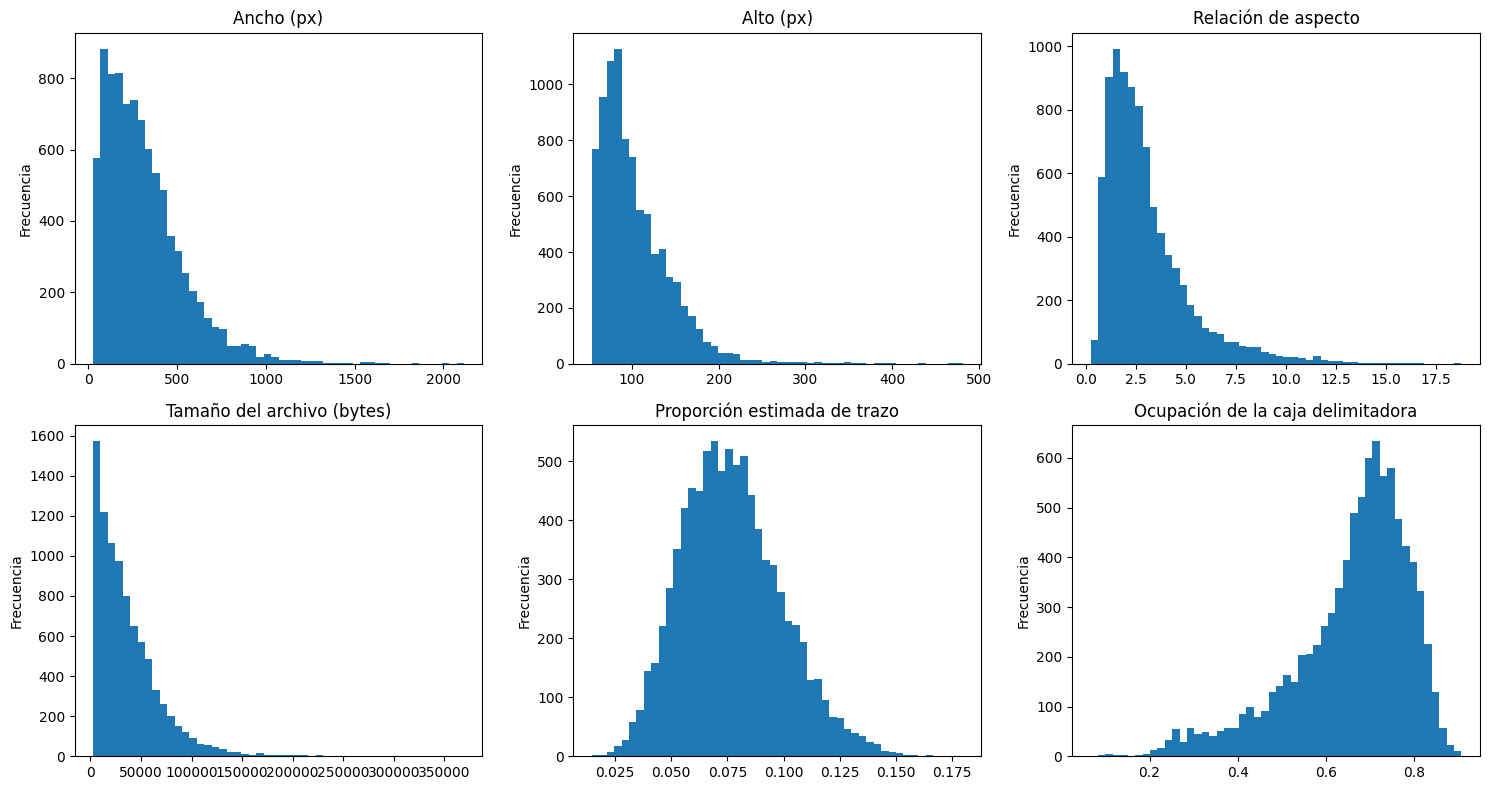

In [6]:
# Resume las variables visuales y grafica sus distribuciones principales.
columnas_visuales = [
    "ancho", "alto", "relacion_aspecto", "bytes_archivo",
    "proporcion_trazo", "ancho_caja", "alto_caja", "ocupacion_caja",
]
display(df_muestras[columnas_visuales].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T)

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
graficas = [
    ("ancho", "Ancho (px)"),
    ("alto", "Alto (px)"),
    ("relacion_aspecto", "Relación de aspecto"),
    ("bytes_archivo", "Tamaño del archivo (bytes)"),
    ("proporcion_trazo", "Proporción estimada de trazo"),
    ("ocupacion_caja", "Ocupación de la caja delimitadora"),
]
for eje, (columna, titulo) in zip(ejes.ravel(), graficas):
    eje.hist(df_muestras[columna].dropna(), bins=50)
    eje.set_title(titulo)
    eje.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## 6. Auditoría de tokens LaTeX

La tokenización oficial disponible en `caption.txt` está separada por espacios, por lo que se usa `split()`. Se reportan frecuencias absolutas, proporciones sobre todos los tokens y presencia por expresión. No se intenta reinterpretar ni recompilar el LaTeX.

In [7]:
# Tokeniza cada referencia y calcula longitud, vocabulario y balance simple de llaves.
def tokenizar(latex):
    return latex.split()

df_muestras["tokens"] = df_muestras["latex"].map(tokenizar)
df_muestras["longitud_tokens"] = df_muestras["tokens"].map(len)
df_muestras["llaves_abren"] = df_muestras["latex"].str.count(r"\{")
df_muestras["llaves_cierran"] = df_muestras["latex"].str.count(r"\}")
df_muestras["llaves_balanceadas"] = df_muestras["llaves_abren"] == df_muestras["llaves_cierran"]

conteo_tokens = Counter(token for tokens in df_muestras["tokens"] for token in tokens)
total_tokens = sum(conteo_tokens.values())
presencia_tokens = Counter(token for tokens in df_muestras["tokens"] for token in set(tokens))

df_tokens = pd.DataFrame(
    [
        {
            "token": token,
            "frecuencia": frecuencia,
            "proporcion_tokens": frecuencia / total_tokens if total_tokens else np.nan,
            "expresiones_con_token": presencia_tokens[token],
            "proporcion_expresiones": presencia_tokens[token] / len(df_muestras) if len(df_muestras) else np.nan,
        }
        for token, frecuencia in conteo_tokens.items()
    ]
).sort_values(["frecuencia", "token"], ascending=[False, True], ignore_index=True)

resumen_latex = pd.Series(
    {
        "expresiones": len(df_muestras),
        "referencias_unicas": df_muestras["latex"].nunique(),
        "tokens_totales": total_tokens,
        "vocabulario": len(conteo_tokens),
        "expresiones_vacias": int(df_muestras["latex"].eq("").sum()),
        "expresiones_con_llaves_desbalanceadas": int((~df_muestras["llaves_balanceadas"]).sum()),
    },
    name="cantidad",
)
display(resumen_latex.to_frame())
display(df_muestras["longitud_tokens"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).to_frame())
display(df_tokens.head(50))

,cantidad
expresiones,8834
referencias_unicas,4832
tokens_totales,137733
vocabulario,109
expresiones_vacias,0
expresiones_con_llaves_desbalanceadas,0


,longitud_tokens
count,8834.000000
mean,15.591238
std,12.391209
min,1.000000
1%,1.000000
5%,1.000000
50%,13.000000
95%,38.000000
99%,56.000000
max,97.000000


,token,frecuencia,proporcion_tokens,expresiones_con_token,proporcion_expresiones
0,{,19976,0.145034,5917,0.669799
1,},19976,0.145034,5917,0.669799
2,1,6207,0.045065,3467,0.392461
3,2,6190,0.044942,3556,0.402536
4,^,6099,0.044281,3424,0.387593
5,+,5406,0.039250,3383,0.382952
6,x,5031,0.036527,2506,0.283677
7,_,4834,0.035097,2396,0.271225
8,-,4305,0.031256,2894,0.327598
9,(,3939,0.028599,2581,0.292167


In [8]:
# Revisa convenciones de presentación sin asumir que deban eliminarse.
tokens_convencion = [
    r"\limits", r"\nolimits", r"\left", r"\right",
    r"\displaystyle", r"\textstyle", r"\,", r"\!", r"\;", r"\quad",
]
auditoria_convenciones = pd.DataFrame(
    [
        {
            "token": token,
            "frecuencia": conteo_tokens[token],
            "expresiones_con_token": presencia_tokens[token],
            "proporcion_expresiones": presencia_tokens[token] / len(df_muestras),
        }
        for token in tokens_convencion
    ]
)
display(auditoria_convenciones)

# Presenta ejemplos con \limits y el token inmediatamente anterior para estudiar su contexto.
filas_limits = df_muestras[df_muestras["tokens"].map(lambda ts: r"\limits" in ts)].copy()
contextos_limits = Counter()
for tokens in filas_limits["tokens"]:
    for indice, token in enumerate(tokens):
        if token == r"\limits":
            previo = tokens[indice - 1] if indice > 0 else "<INICIO>"
            contextos_limits[previo] += 1

display(pd.DataFrame(contextos_limits.most_common(), columns=["token_previo", "frecuencia"]))
display(filas_limits[["id", "latex", "longitud_tokens"]].head(50))

,token,frecuencia,expresiones_con_token,proporcion_expresiones
0,\limits,1046,907,0.102671
1,\nolimits,0,0,0.000000
2,\left,0,0,0.000000
3,\right,0,0,0.000000
4,\displaystyle,0,0,0.000000
5,\textstyle,0,0,0.000000
6,"\,",0,0,0.000000
7,\!,0,0,0.000000
8,\;,0,0,0.000000
9,\quad,0,0,0.000000


,token_previo,frecuencia
0,\sum,391
1,\int,368
2,\lim,287


,id,latex,longitud_tokens
1120,formulaire013-equation006,\int \limits _ { a } ^ { b } f,11
1691,formulaire018-equation053,\int \limits _ { a } ^ { b } \phi,11
2215,MfrDB3035,\sum \limits _ { n = 1 } ^ { \infty } ( b _ { n } - b _ { n + 1 } ),27
2329,2009213-137-208,\int \limits _ { v } ^ { \mu e } e d A,14
2371,MfrDB3494,\sum \limits _ { n = 0 } ^ { \infty } f _ { n } ( x ),20
2383,200926-1617-256,\int \limits _ { V } ^ { \gamma } M d \beta,13
2644,200924-1312-199,\int \limits _ { t } ^ { h } t d f,13
2724,2009213-137-3,\int \limits _ { n } ^ { \alpha } Y d k,13
2746,2009213-139-245,\sum \limits _ { \gamma > I } [ 2 ],11
2767,200922-949-7,\sum \limits _ { m } f ( m + 3 ),12


## 7. Variantes que solo difieren por `\limits`

Esta sección agrupa referencias después de retirar exclusivamente el token `\limits`. Sirve para estimar el alcance de esa diferencia de convención, no para aprobar automáticamente la normalización. Se conservan las variantes originales para revisión.

In [9]:
# Retira únicamente tokens exactamente iguales a \limits; no altera subcadenas.
def sin_limits(latex):
    return " ".join(token for token in tokenizar(latex) if token != r"\limits")

df_muestras["latex_sin_limits"] = df_muestras["latex"].map(sin_limits)

variantes_limits = (
    df_muestras.groupby("latex_sin_limits", dropna=False)
    .agg(
        n_muestras=("id", "size"),
        n_variantes_originales=("latex", "nunique"),
        variantes=("latex", lambda serie: sorted(set(serie))),
        ids=("id", lambda serie: list(serie)),
    )
    .reset_index()
)
variantes_limits = variantes_limits[variantes_limits["n_variantes_originales"] > 1]
variantes_limits = variantes_limits.sort_values(
    ["n_muestras", "n_variantes_originales"], ascending=False
)

print(f"Grupos con variantes que colapsan al retirar solo \\limits: {len(variantes_limits):,}")
display(variantes_limits.head(50))

Grupos con variantes que colapsan al retirar solo \limits: 0


,latex_sin_limits,n_muestras,n_variantes_originales,variantes,ids


## 8. Referencias repetidas e imágenes asociadas

Una referencia repetida puede corresponder a distintas escrituras de la misma expresión. Por eso se registran dimensiones y huellas SHA-256 de los archivos. Una huella igual indica que los bytes de las imágenes son exactamente iguales; dimensiones distintas o huellas distintas indican archivos diferentes, aunque compartan ground truth.

In [10]:
# Calcula una huella reproducible sobre los bytes de cada archivo.
def sha256_archivo(ruta, bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            fragmento = archivo.read(bloque)
            if not fragmento:
                break
            digest.update(fragmento)
    return digest.hexdigest()

df_muestras["sha256_imagen"] = df_muestras["ruta_imagen"].map(
    lambda ruta: sha256_archivo(ruta) if pd.notna(ruta) else pd.NA
)

grupos_repetidos = (
    df_muestras.groupby("latex", dropna=False)
    .agg(
        n_muestras=("id", "size"),
        n_ids=("id", "nunique"),
        n_imagenes_exactas=("sha256_imagen", "nunique"),
        n_dimensiones=("ancho", lambda s: len(set(zip(s, df_muestras.loc[s.index, "alto"])))),
        ids=("id", lambda serie: list(serie)),
        dimensiones=("ancho", lambda s: sorted(set(zip(s, df_muestras.loc[s.index, "alto"])))),
    )
    .reset_index()
)
grupos_repetidos = grupos_repetidos[grupos_repetidos["n_muestras"] > 1]
grupos_repetidos = grupos_repetidos.sort_values("n_muestras", ascending=False)

print(f"Referencias repetidas: {len(grupos_repetidos):,}")
print(f"Muestras dentro de grupos repetidos: {grupos_repetidos['n_muestras'].sum():,}")
display(grupos_repetidos.head(50))

Referencias repetidas: 447
Muestras dentro de grupos repetidos: 4,449


,latex,n_muestras,n_ids,n_imagenes_exactas,n_dimensiones,ids,dimensiones
2776,\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } },58,58,31,31,"[KME2G3_17_sub_95, TrainData2_15_sub_95, TrainData2_26_sub_95, KME2G3_29_sub_95, KME2G3_27_sub_95, TrainData2_25_sub_95, TrainData2_10_sub_95, KME2G3_12_sub...","[(209, 103), (225, 95), (229, 107), (231, 98), (255, 99), (260, 97), (261, 97), (263, 94), (266, 108), (270, 104), (271, 106), (278, 114), (280, 96), (280, ..."
4646,x _ { x } ^ { x } + y _ { y } ^ { y } + z _ { z } ^ { z } - x - y - z,31,31,31,31,"[KME2G3_11_sub_22, KME2G3_12_sub_22, KME2G3_6_sub_22, KME2G3_26_sub_22, KME2G3_7_sub_22, KME2G3_20_sub_22, KME2G3_18_sub_22, KME2G3_5_sub_22, KME2G3_0_sub_2...","[(442, 109), (447, 125), (466, 112), (469, 102), (477, 105), (492, 108), (513, 135), (514, 124), (549, 120), (554, 115), (557, 97), (557, 115), (557, 116), ..."
3052,\sum \limits _ { i = 2 n + 3 m } ^ { 1 0 } i x,31,31,31,31,"[KME2G3_17_sub_30, KME2G3_0_sub_30, KME2G3_12_sub_30, KME2G3_9_sub_30, KME2G3_7_sub_30, KME2G3_21_sub_30, KME2G3_26_sub_30, KME2G3_3_sub_30, KME2G3_20_sub_3...","[(217, 157), (221, 213), (227, 186), (235, 188), (235, 202), (242, 221), (245, 171), (246, 218), (258, 164), (260, 209), (279, 225), (285, 199), (285, 218),..."
2499,\int \limits _ { \log 3 } ^ { 0 } \frac { 1 } { e ^ { t } + 1 } d t,31,31,31,31,"[KME2G3_23_sub_74, KME2G3_24_sub_74, KME2G3_29_sub_74, KME2G3_18_sub_74, KME2G3_16_sub_74, KME2G3_6_sub_74, KME2G3_10_sub_74, KME2G3_7_sub_74, KME2G3_17_sub...","[(227, 145), (239, 137), (240, 142), (245, 151), (251, 155), (258, 134), (259, 130), (260, 123), (262, 137), (262, 140), (263, 127), (267, 133), (268, 139),..."
4616,x _ { 1 } \times x _ { 2 } \times x _ { 3 } \times x _ { 4 } = X,31,31,31,31,"[KME2G3_23_sub_26, KME2G3_12_sub_26, KME2G3_9_sub_26, KME2G3_29_sub_26, KME2G3_11_sub_26, KME2G3_18_sub_26, KME2G3_17_sub_26, KME2G3_0_sub_26, KME2G3_16_sub...","[(395, 88), (435, 93), (441, 87), (442, 76), (445, 123), (446, 95), (447, 79), (471, 90), (485, 95), (500, 90), (504, 103), (527, 89), (533, 93), (542, 87),..."
2634,\log _ { 2 } \frac { 1 } { 2 } + \log _ { 4 } \frac { 2 } { 4 },31,31,31,31,"[KME2G3_17_sub_35, KME2G3_9_sub_35, KME2G3_26_sub_35, KME2G3_12_sub_35, KME2G3_7_sub_35, KME2G3_14_sub_35, KME2G3_0_sub_35, KME2G3_23_sub_35, KME2G3_13_sub_...","[(326, 118), (326, 133), (329, 109), (334, 126), (340, 124), (341, 119), (343, 122), (344, 109), (345, 131), (350, 131), (351, 144), (356, 128), (363, 117),..."
2682,\pi \int \limits _ { c } ^ { d } \{ g ( y ) \} ^ { 2 } d y,31,31,31,31,"[KME2G3_14_sub_81, KME2G3_24_sub_81, KME2G3_21_sub_81, KME2G3_8_sub_81, KME2G3_2_sub_81, KME2G3_1_sub_81, KME2G3_7_sub_81, KME2G3_27_sub_81, KME2G3_12_sub_8...","[(208, 108), (226, 101), (226, 121), (243, 105), (244, 104), (248, 116), (248, 127), (250, 107), (251, 116), (253, 121), (254, 107), (258, 129), (259, 104),..."
4804,z _ { 1 } ^ { 2 } + 1 ^ { z } - z _ { 2 } ^ { 2 } + 2 ^ { z },31,31,31,31,"[KME2G3_9_sub_28, KME2G3_6_sub_28, KME2G3_20_sub_28, KME2G3_11_sub_28, KME2G3_14_sub_28, KME2G3_12_sub_28, KME2G3_22_sub_28, KME2G3_3_sub_28, KME2G3_0_sub_2...","[(378, 105), (391, 117), (408, 99), (410, 100), (411, 97), (423, 129), (428, 93), (430, 110), (433, 109), (435, 119), (448, 107), (488, 119), (492, 100), (4..."
1764,[ \frac { 2 } { 3 } x ^ { \frac { 3 } { 2 } } ] _ { 0 } ^ { 1 },30,30,30,30,"[KME2G3_29_sub_65, KME2G3_27_sub_65, KME2G3_14_sub_65, KME2G3_9_sub_65, KME2G3_8_sub_65, KME2G3_26_sub_65, KME2G3_21_sub_65, KME2G3_10_sub_65, KME2G3_15_sub...","[(117, 101), (135, 116), (139, 102), (143, 114), (150, 106), (152, 115), (154, 116), (156, 106), (160, 108), (166, 111), (173, 116), (175, 113), (176, 110),..."
2116,\frac { 2 } { \frac { 3 m - 2 n \times 9 ^ { n } - 9 ^ { m } } { 2 n - 1 } },30,30,30,30,"[KME2G3_9_sub_38, KME2G3_12_sub_38, KME2G3_16_sub_38, KME2G3_17_sub_38, KME2G3_29_sub_38, KME2G3_23_sub_38, KME2G3_13_sub_38, KME2G3_20_sub_38, KME2G3_7_sub...","[(360, 243), (406, 196), (420, 251), (426, 245),

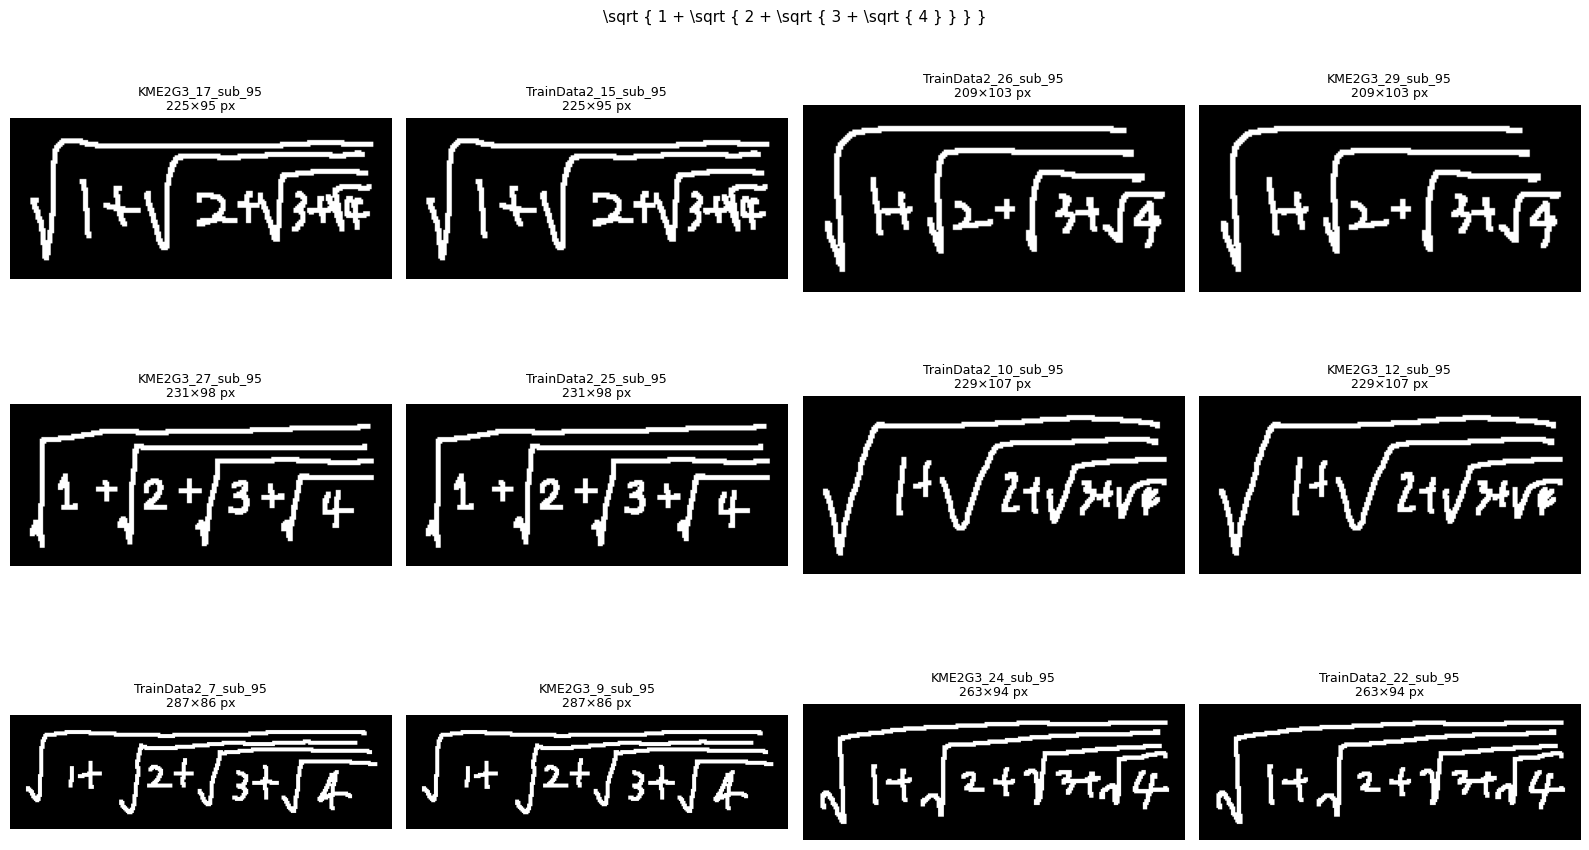

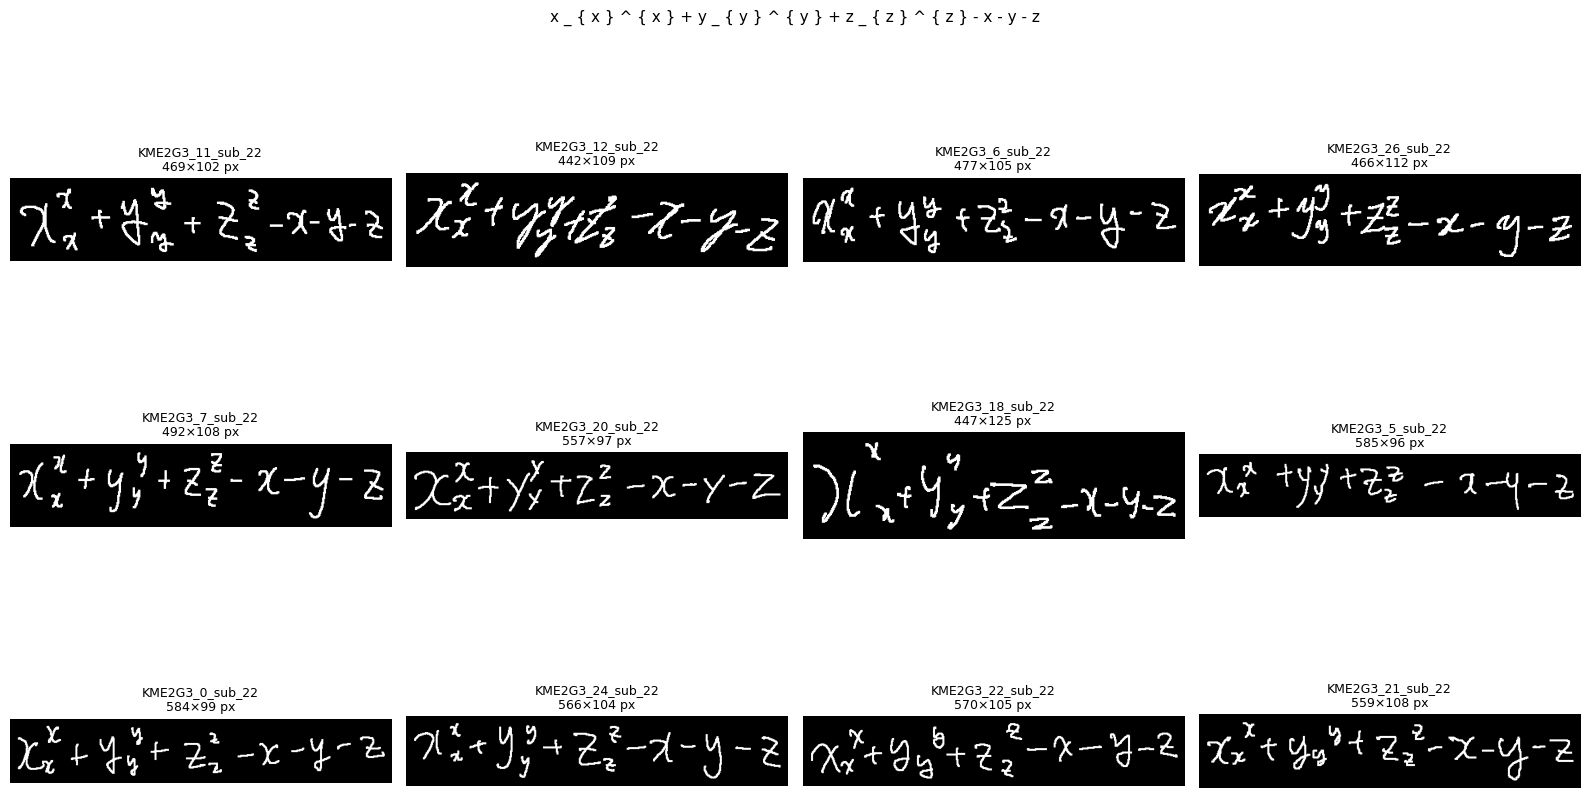

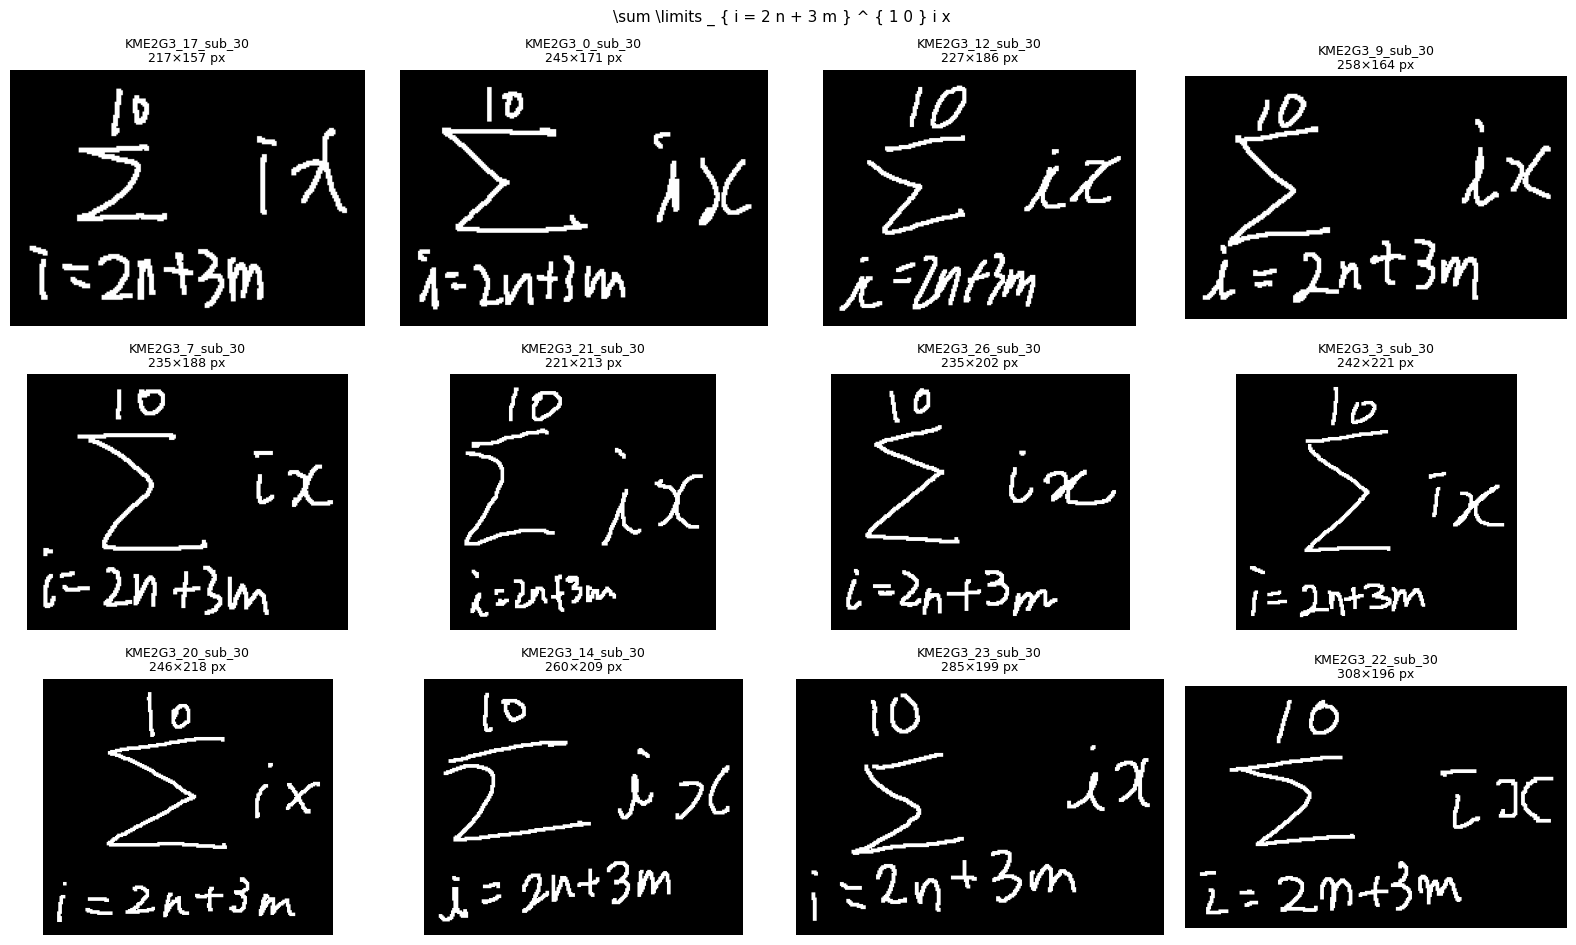

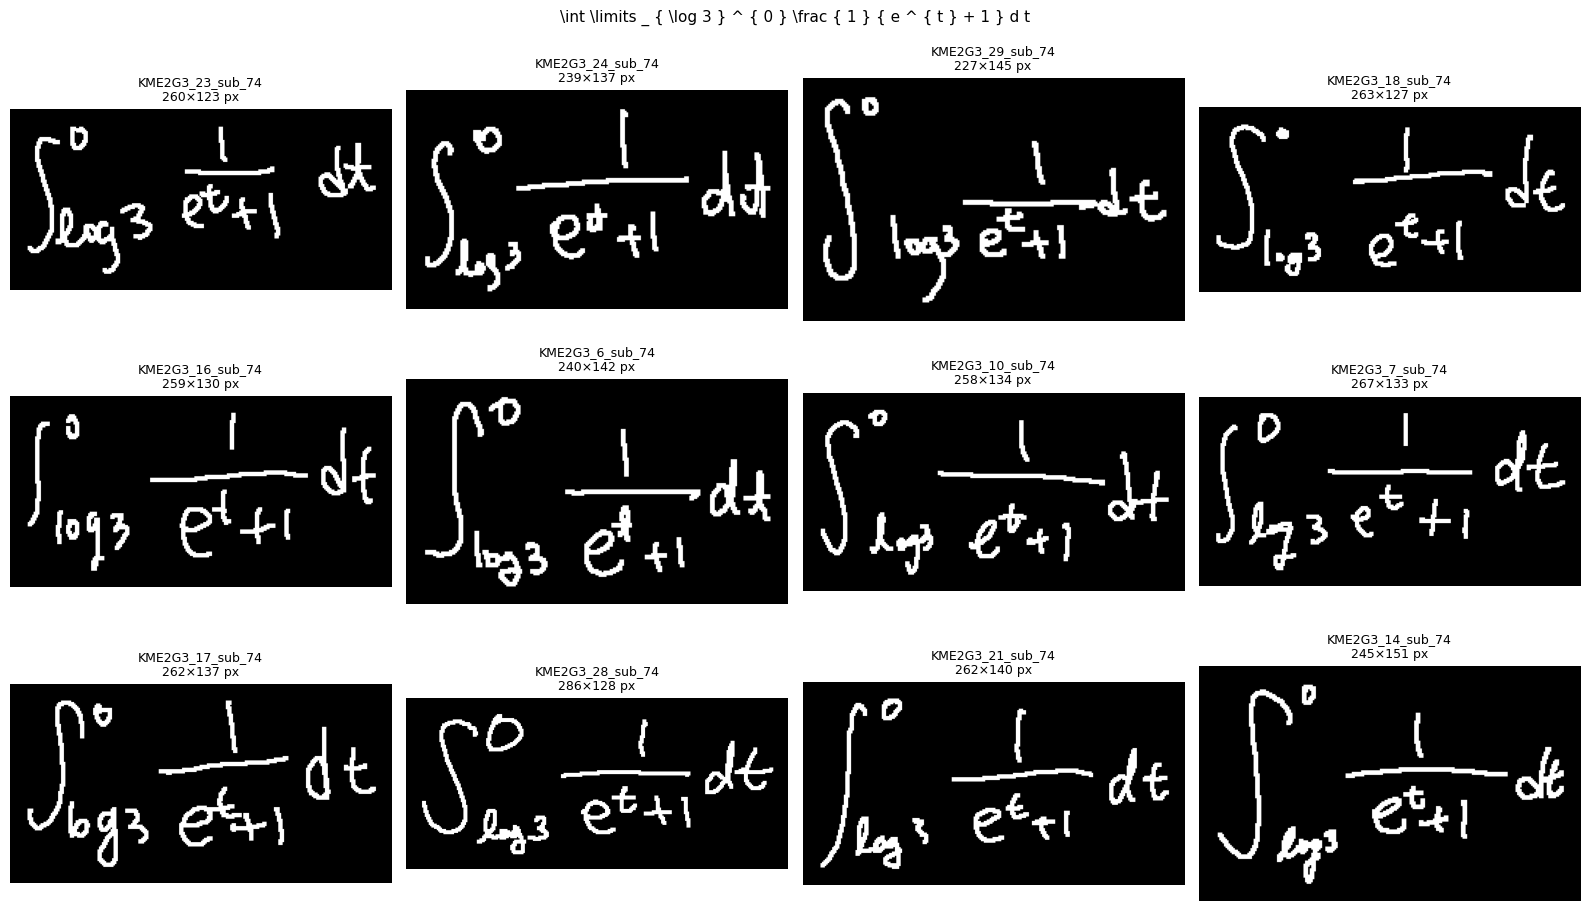

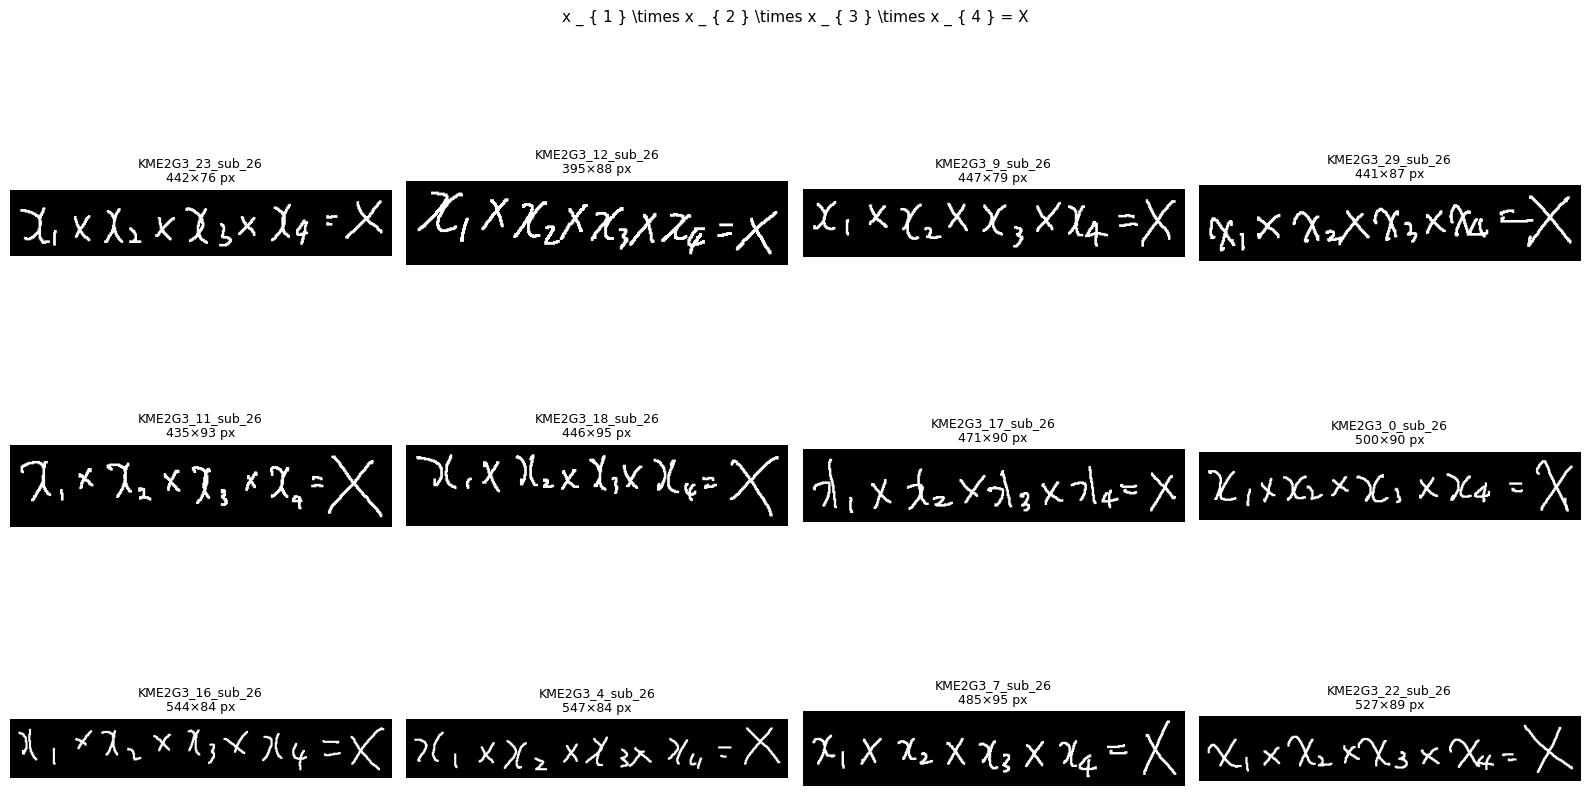

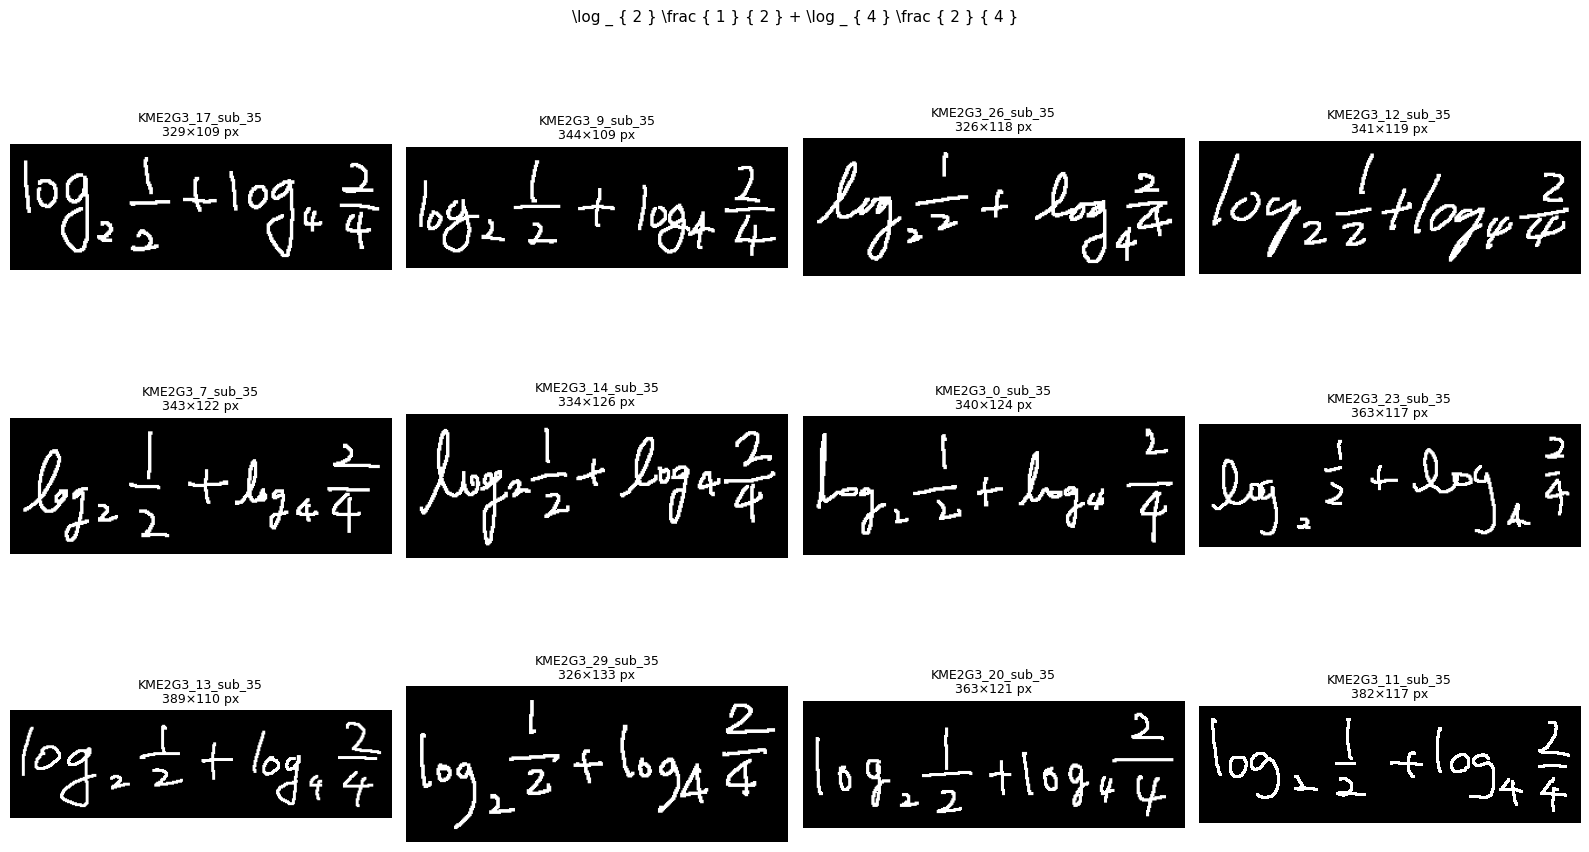

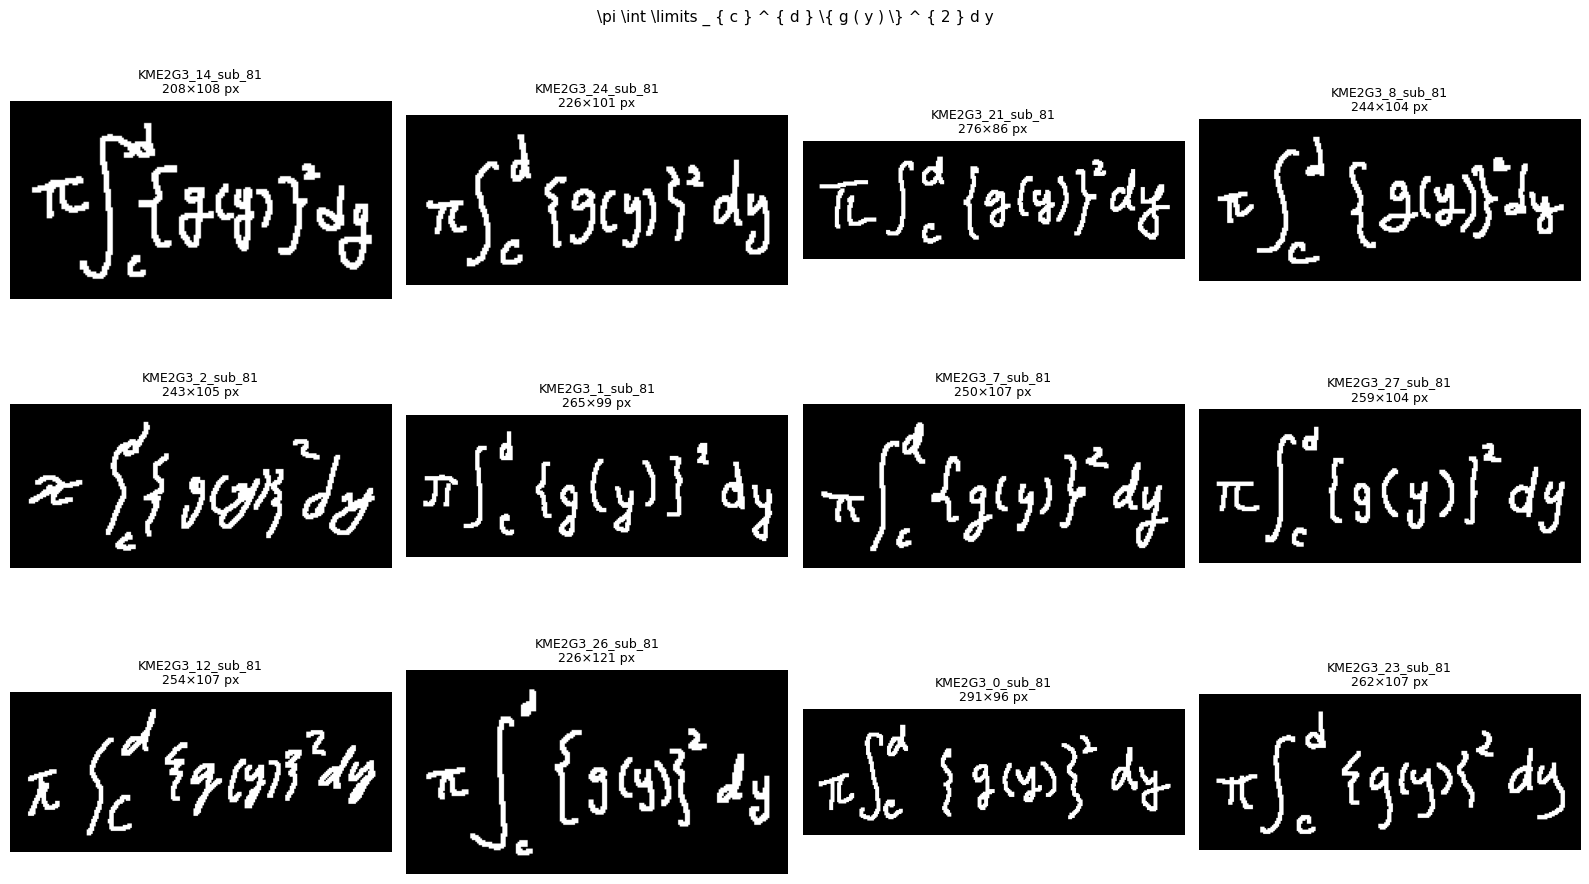

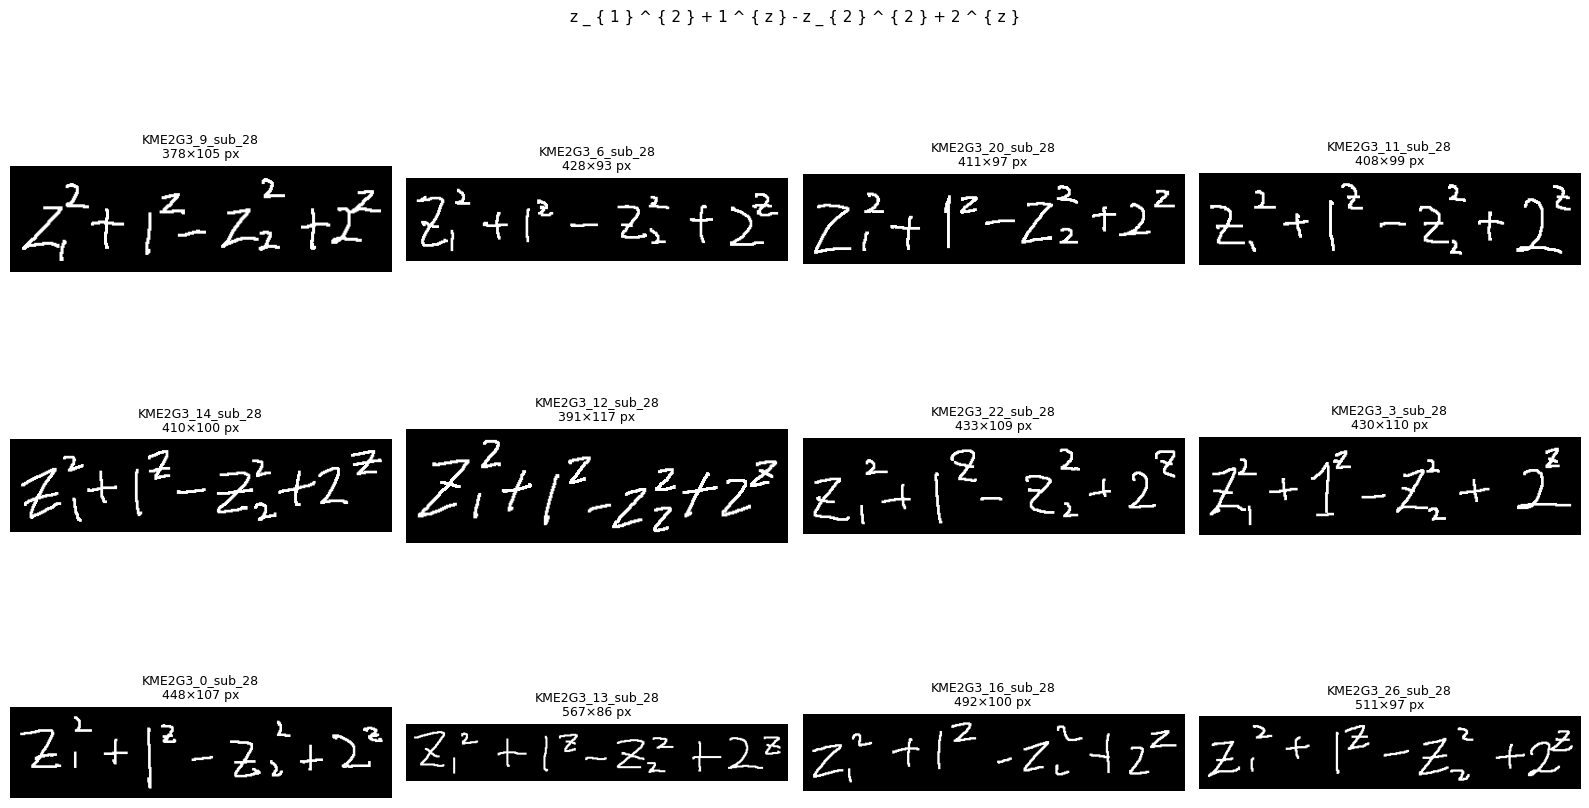

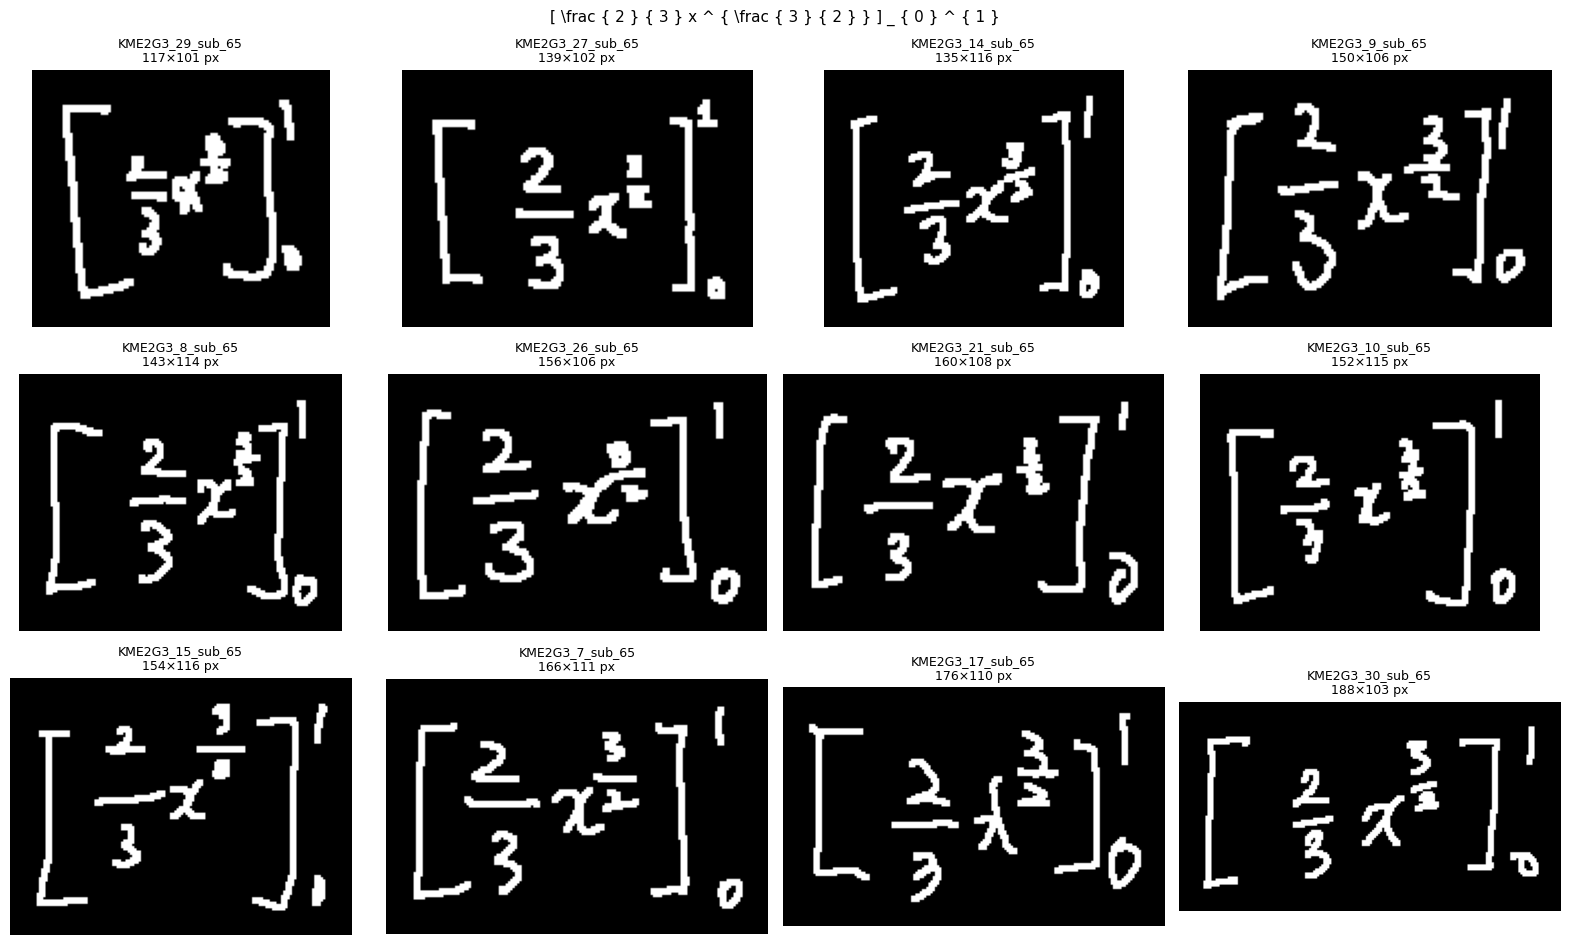

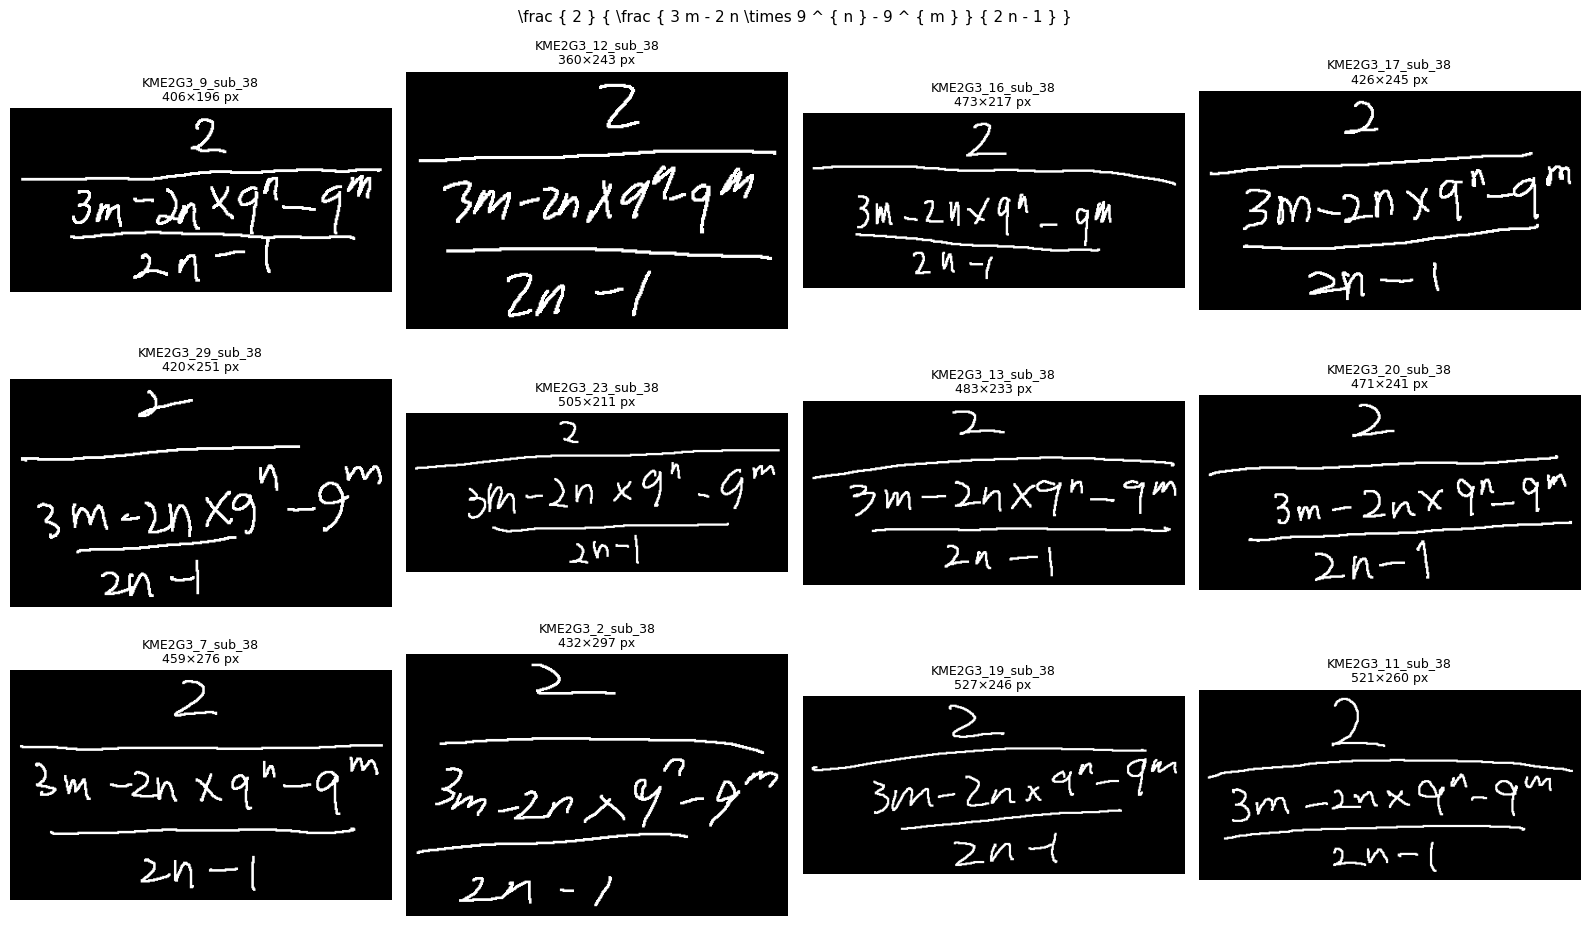

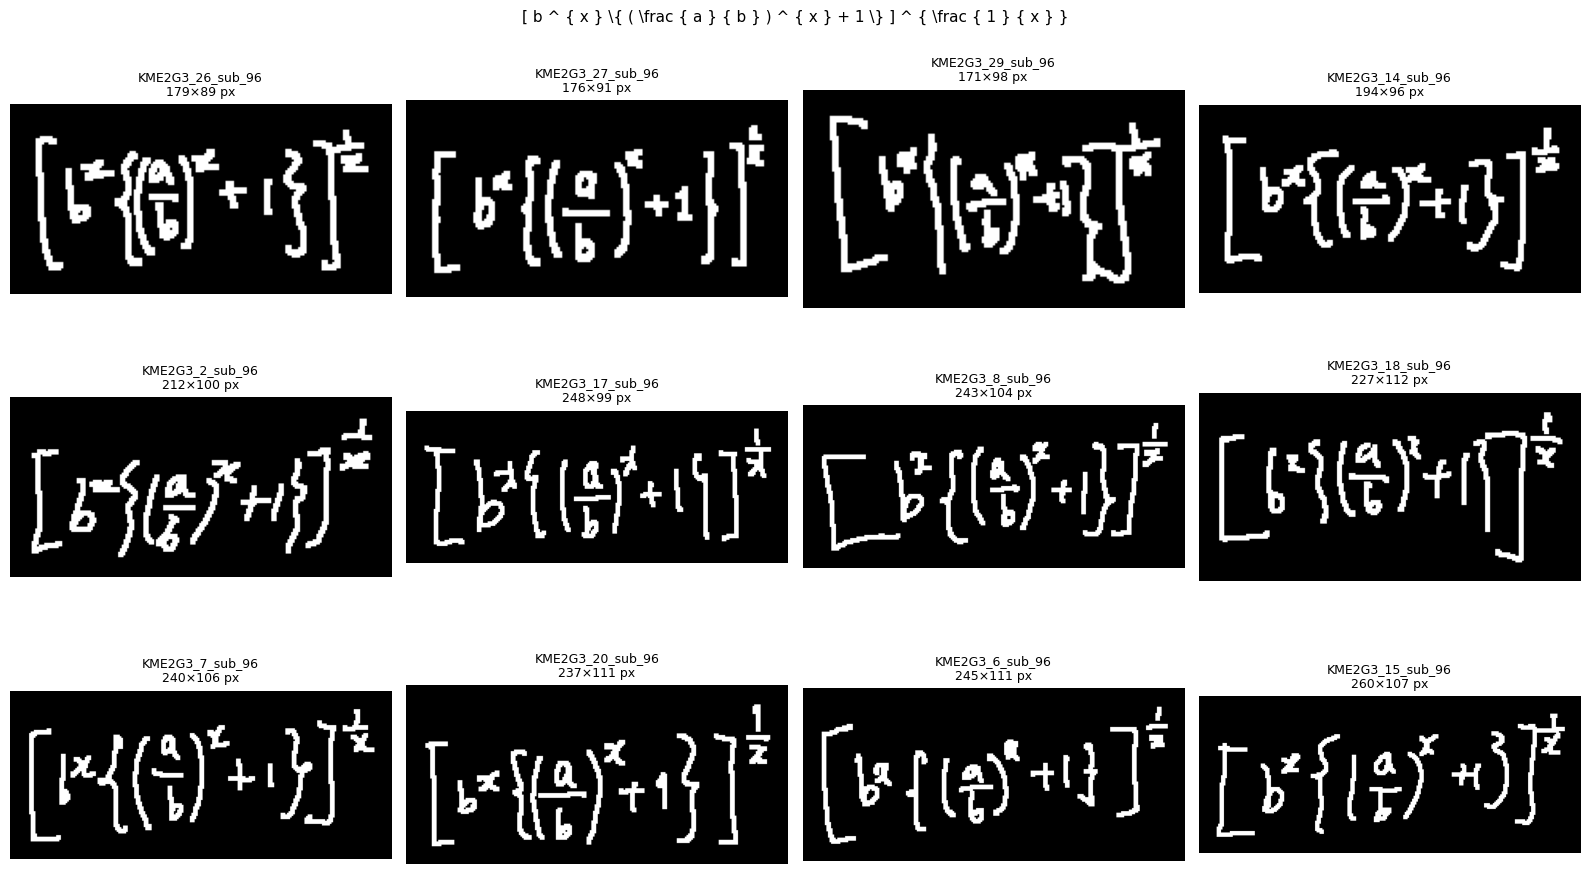

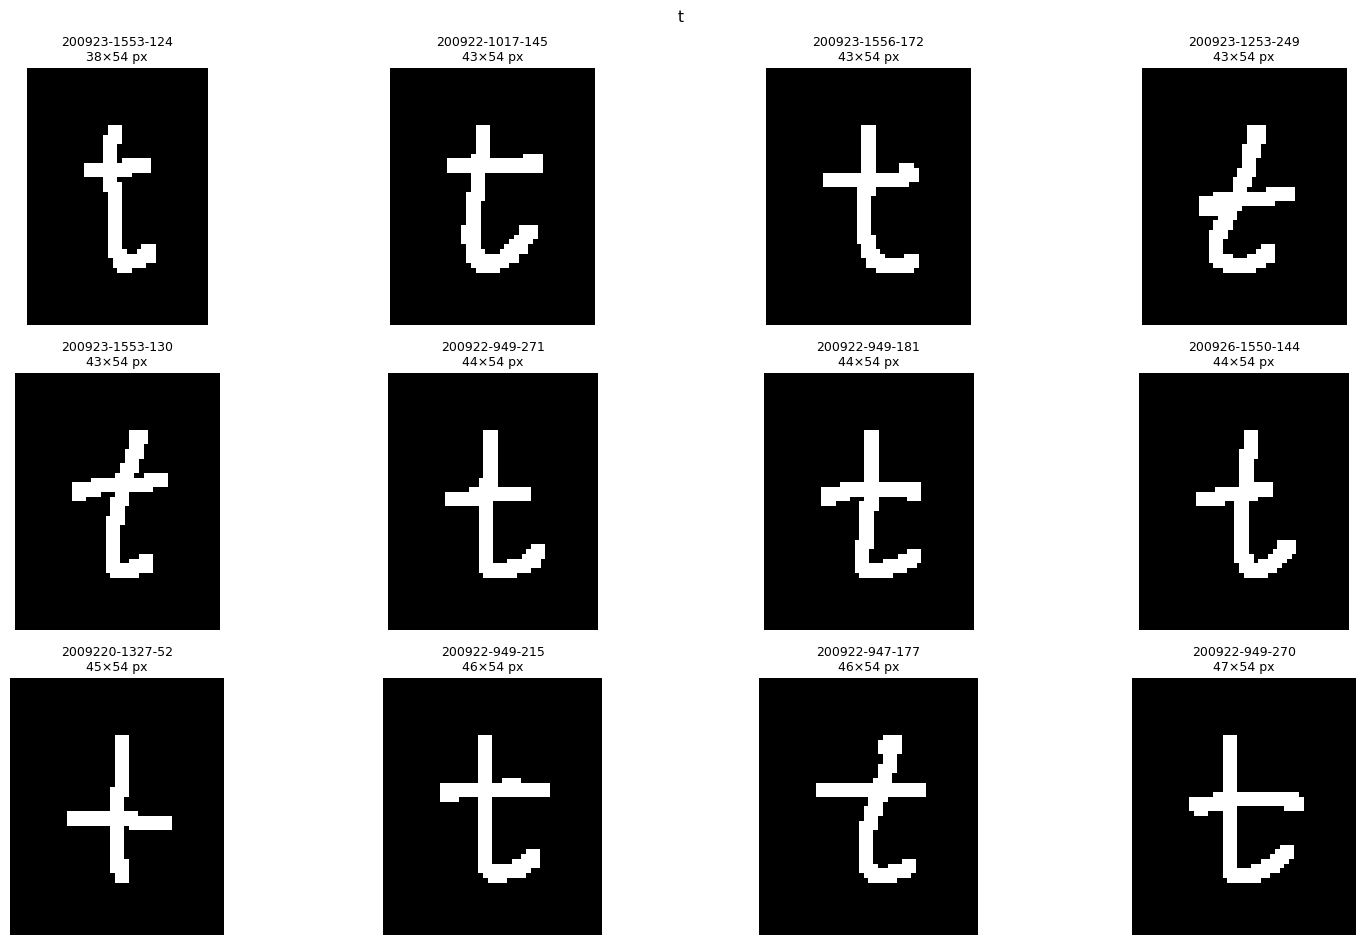

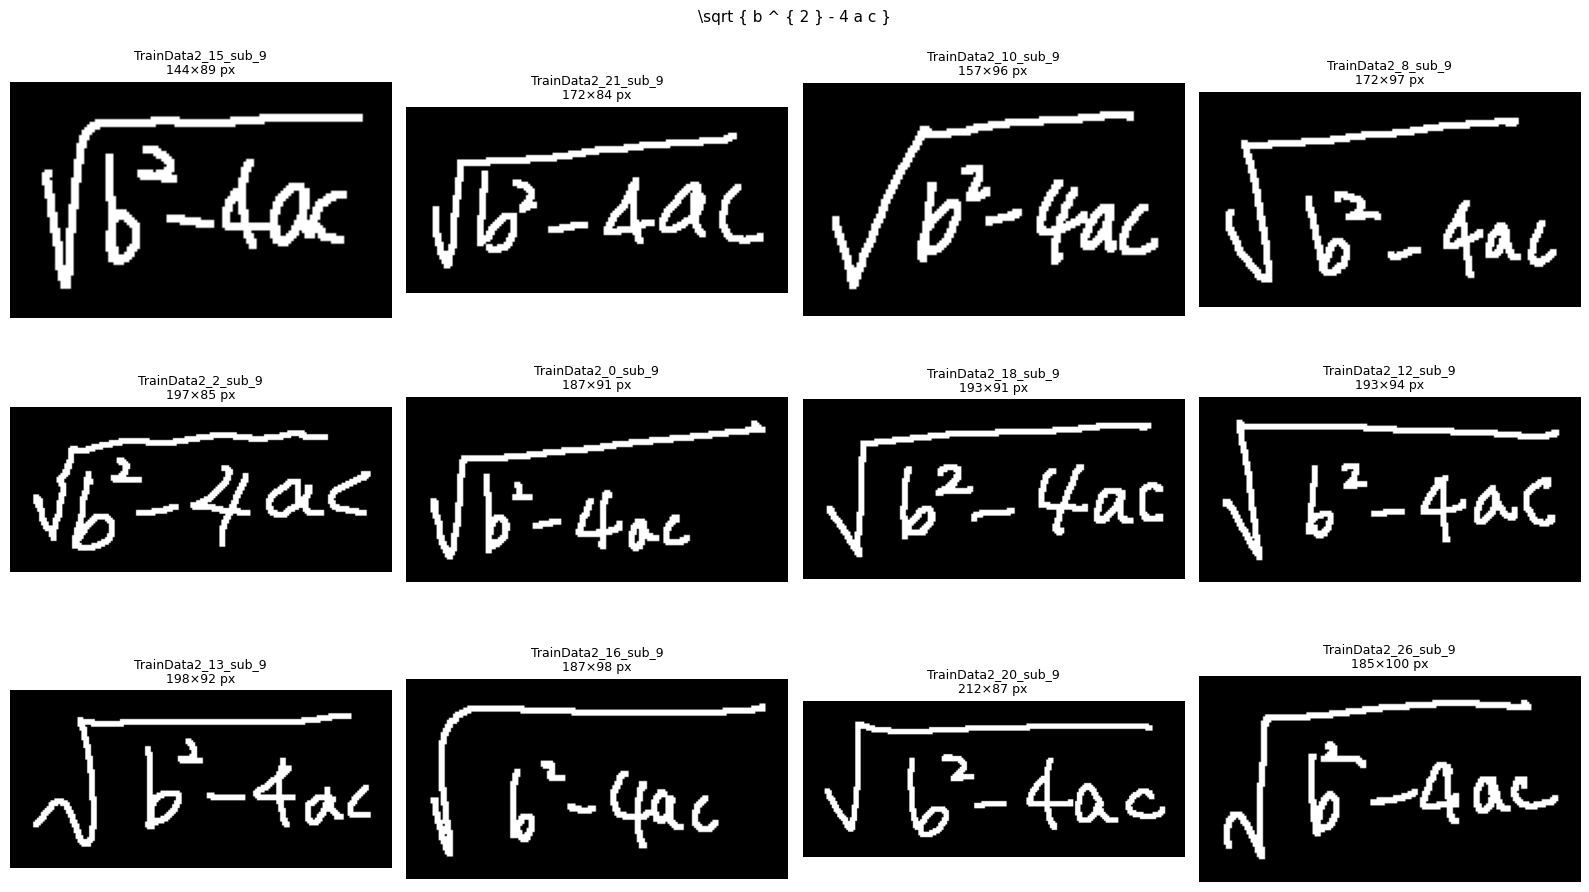

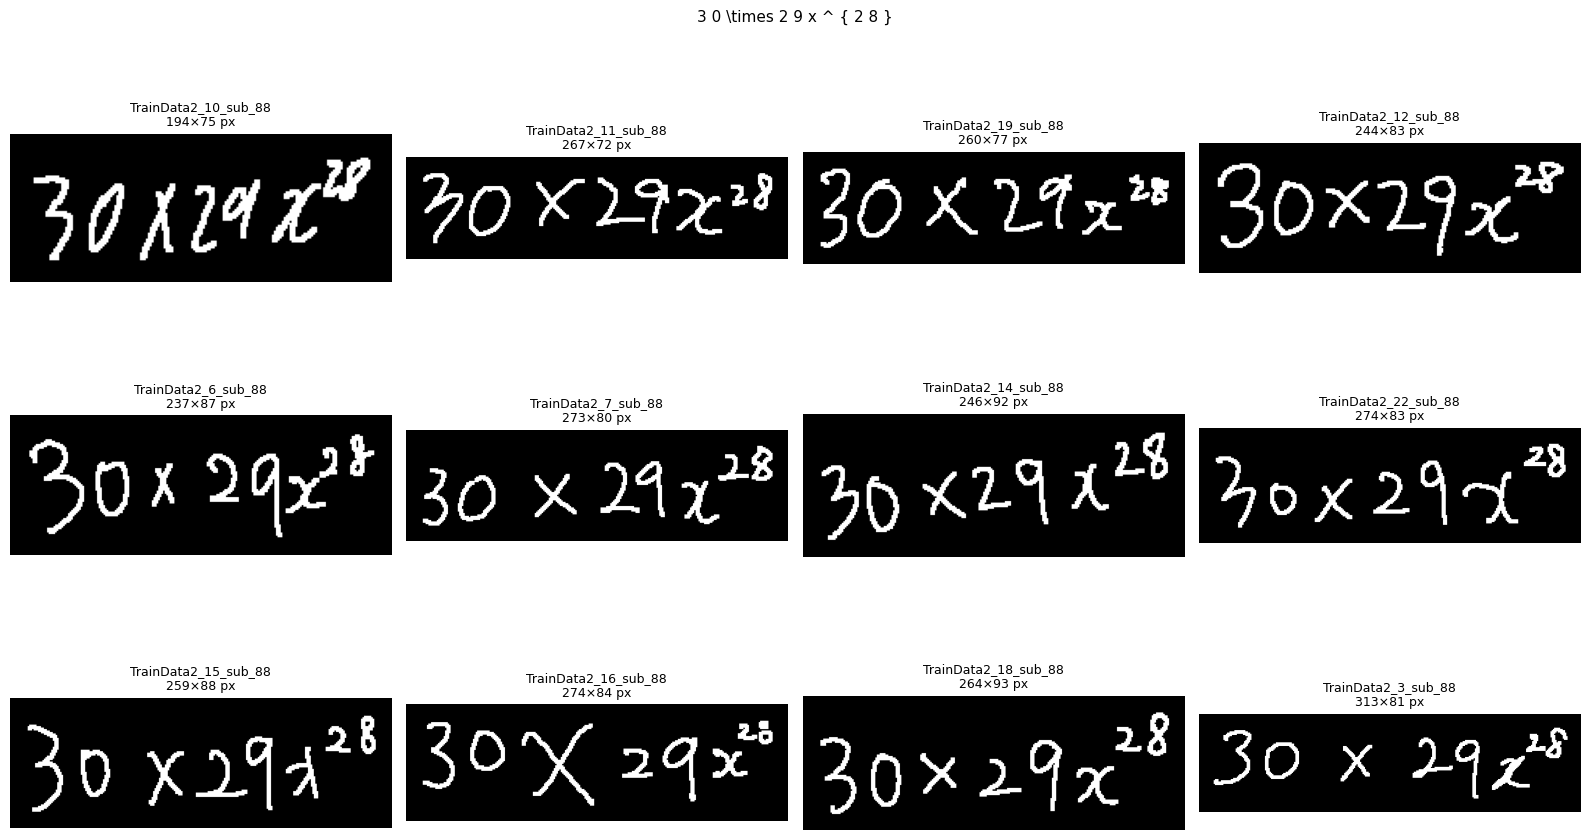

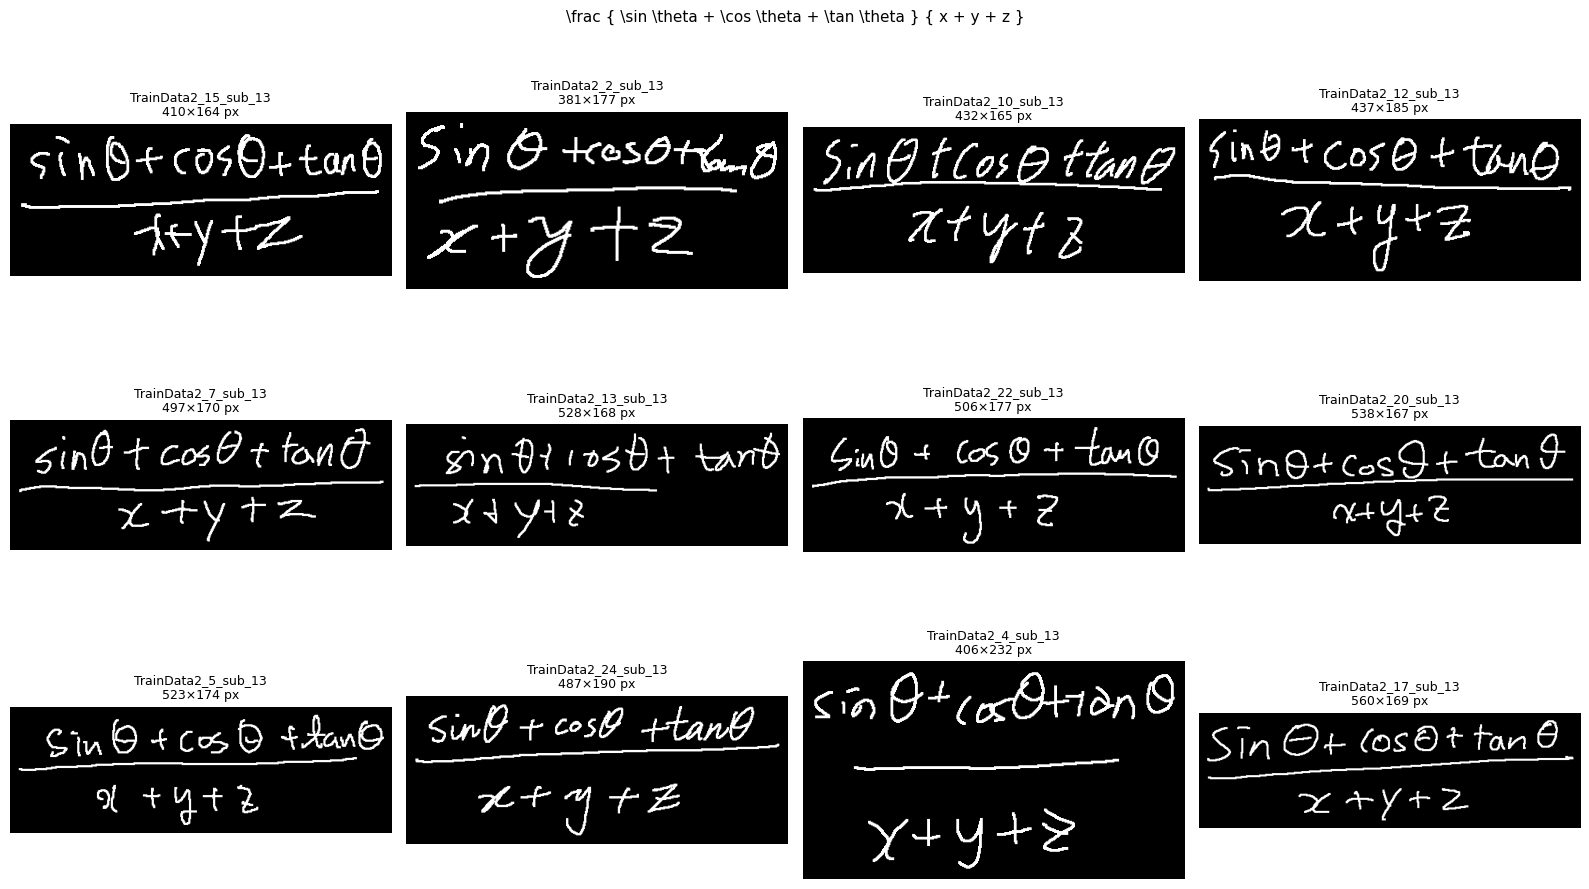

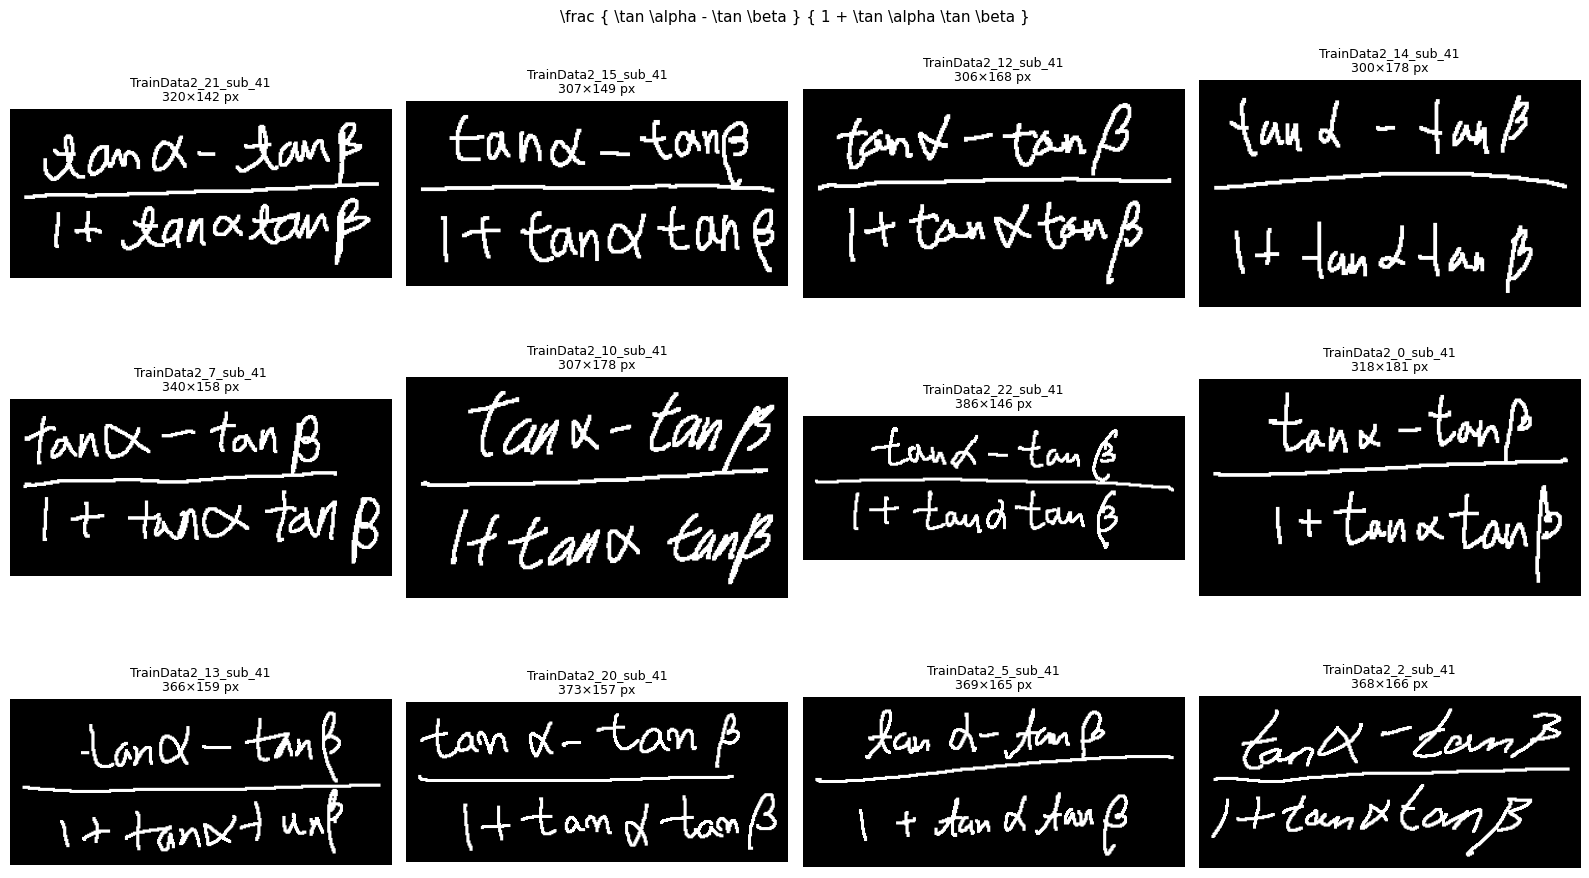

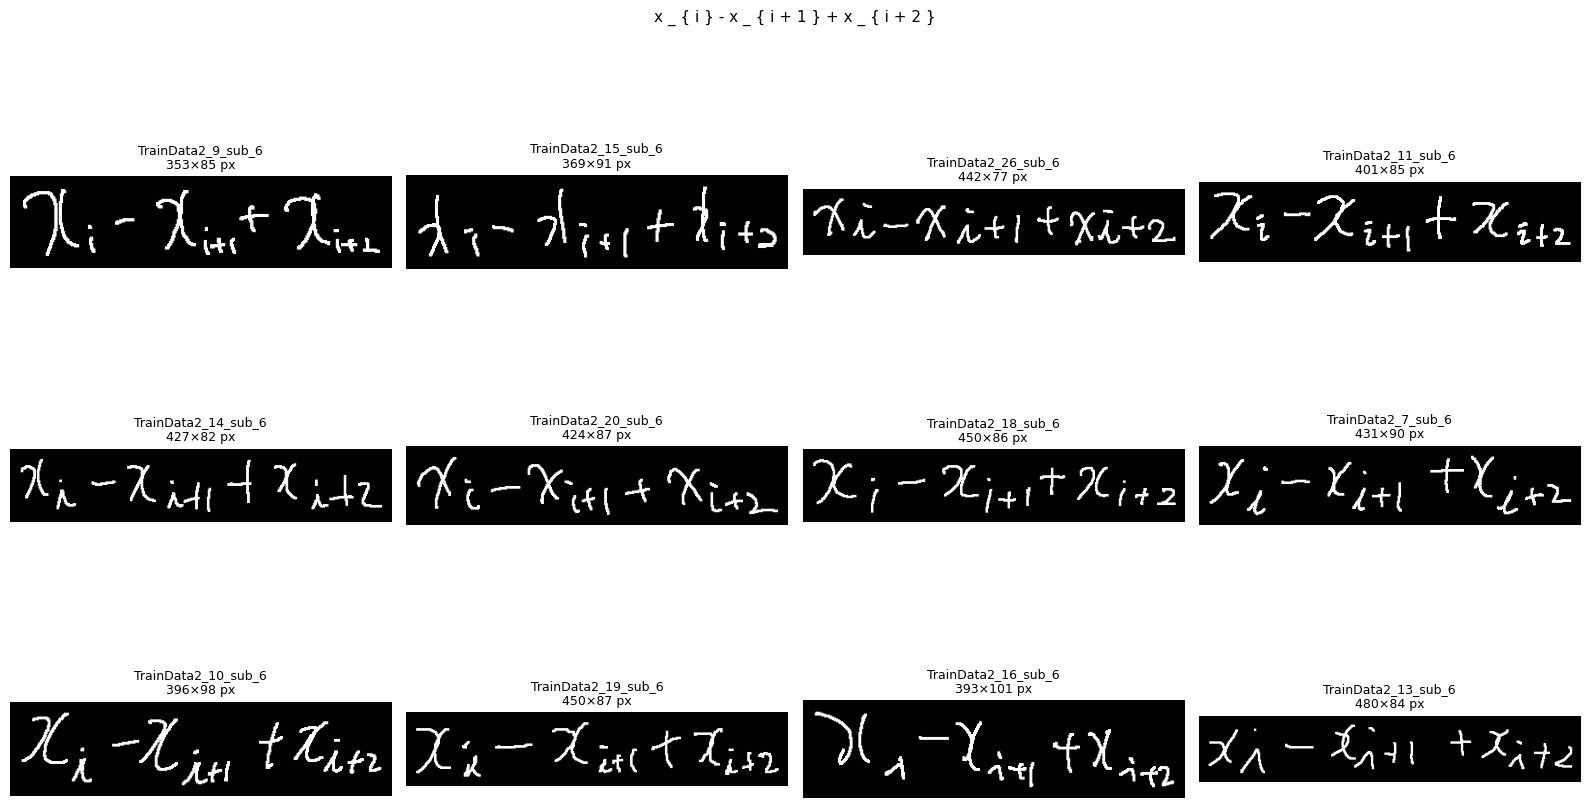

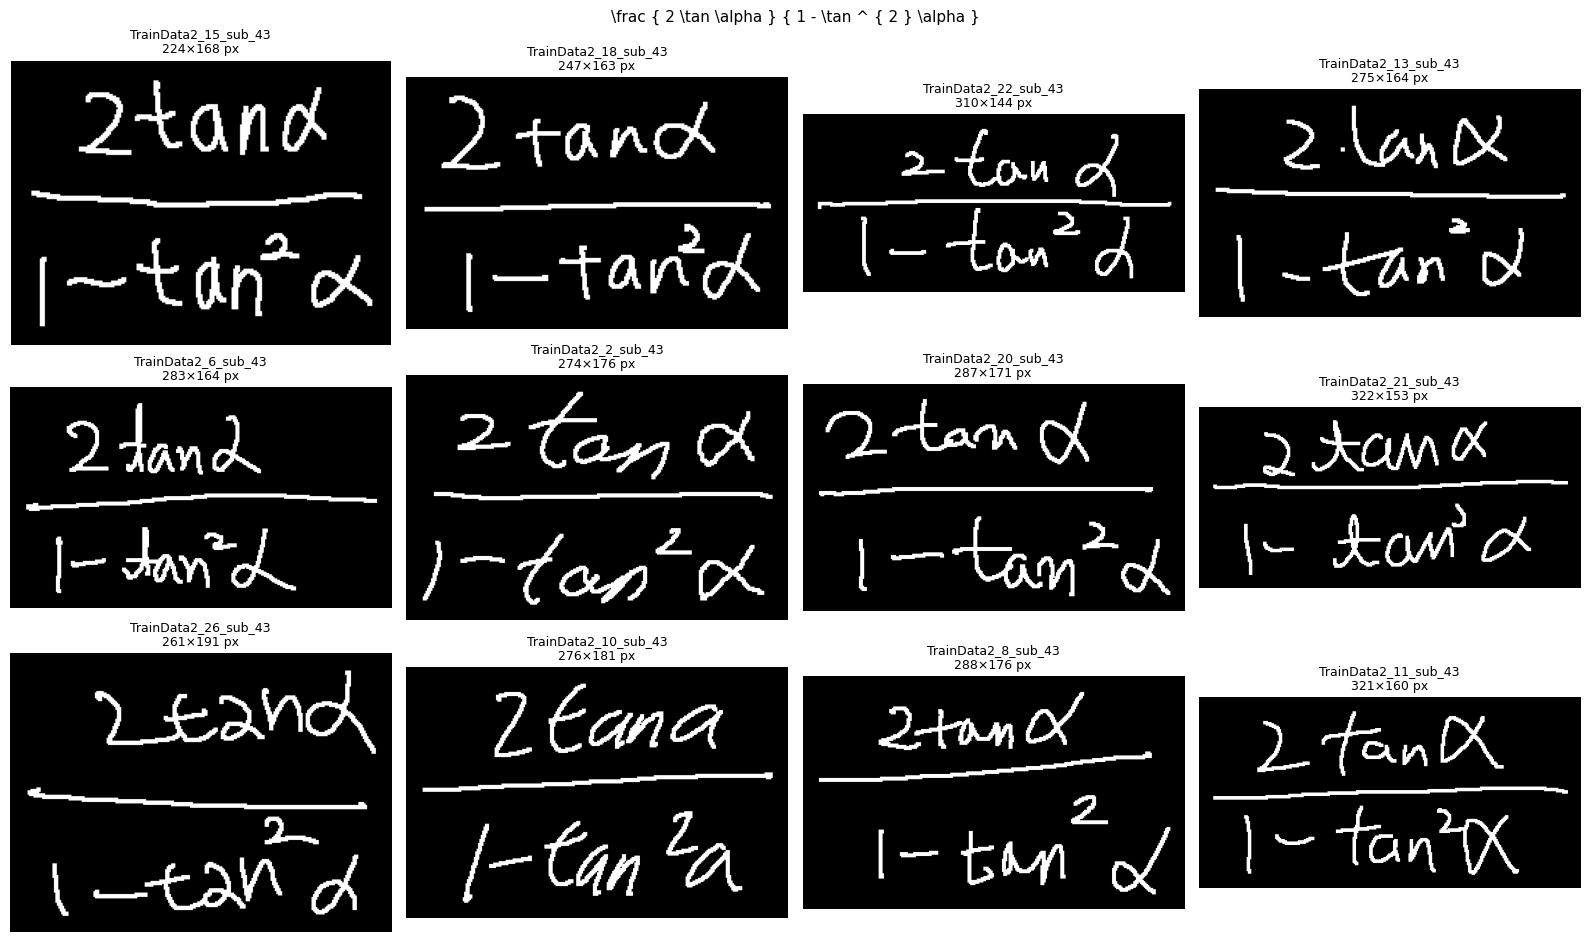

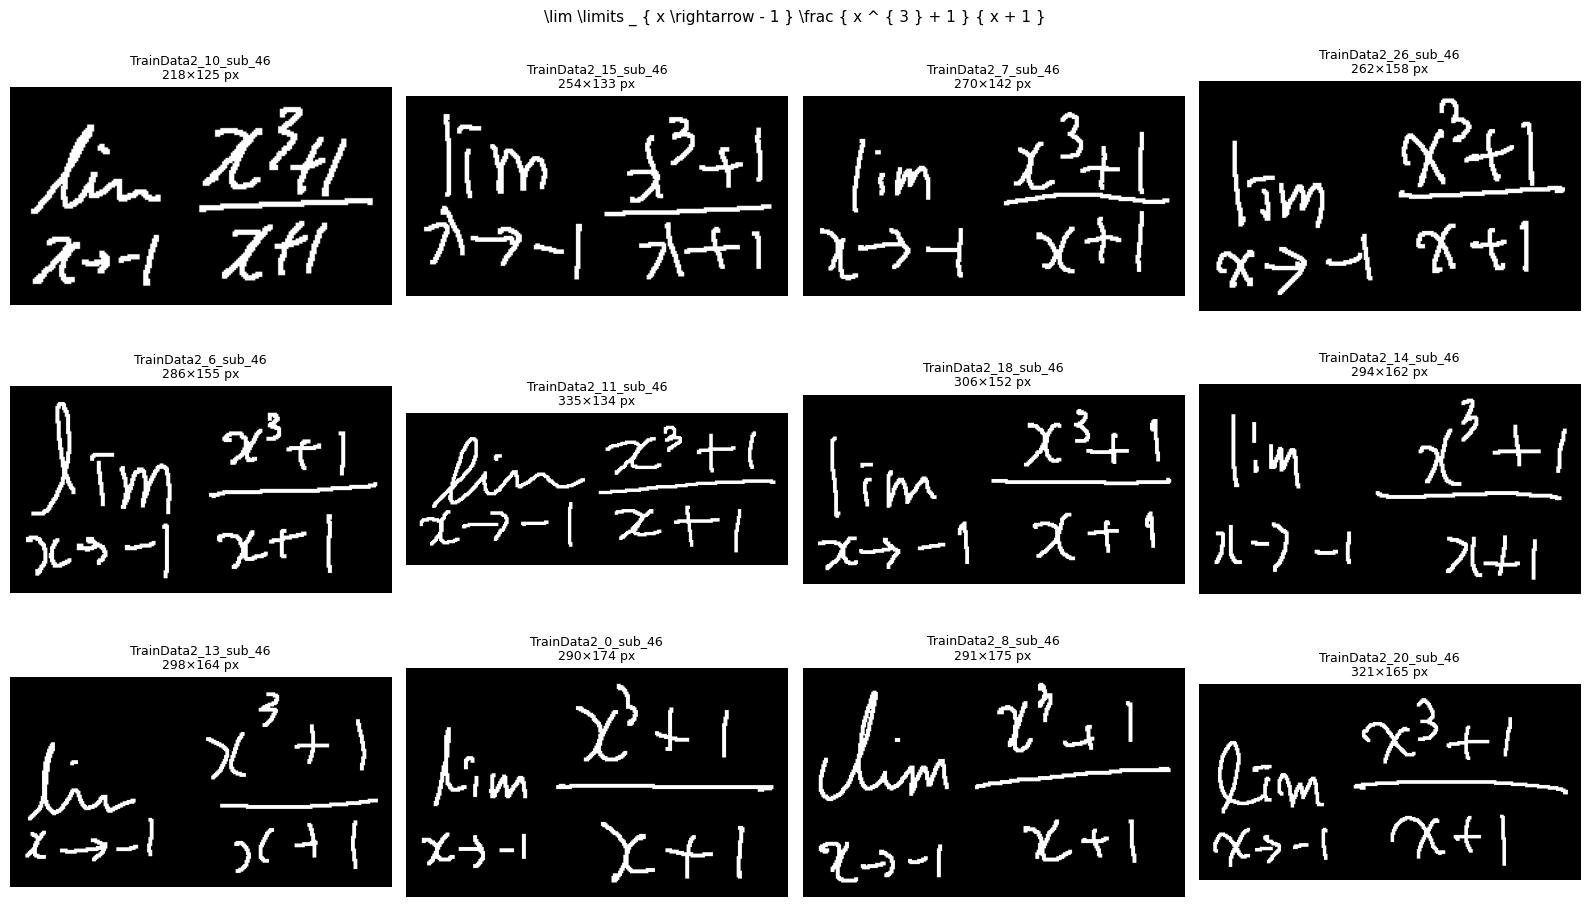

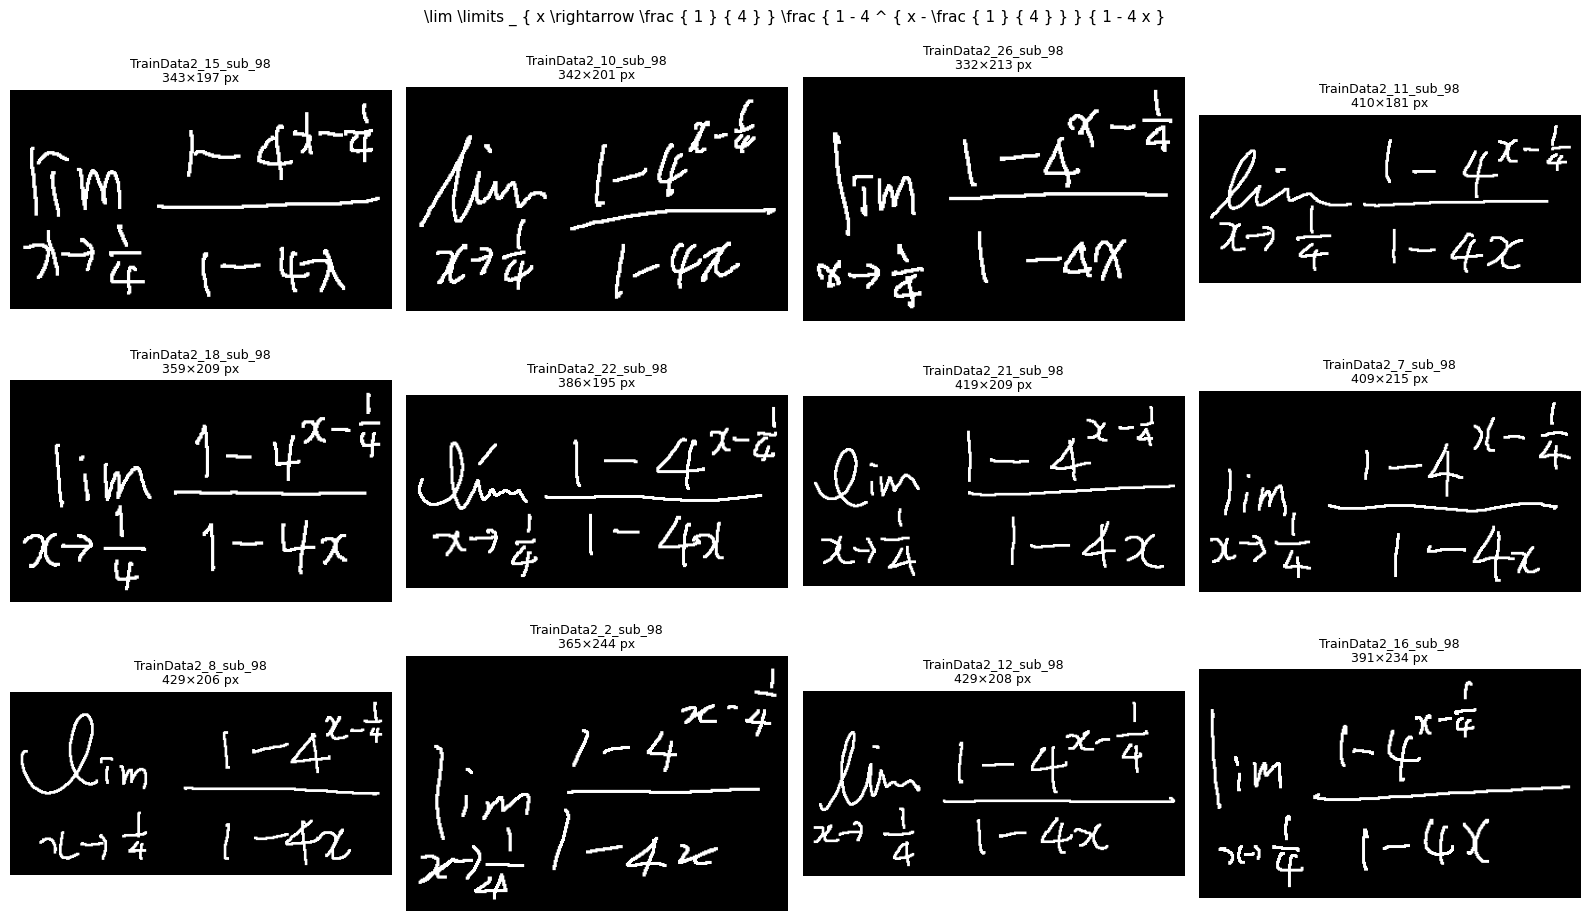

In [11]:
# Visualiza grupos repetidos en lotes limitados para evitar una salida inmanejable.
def visualizar_grupo_repetido(latex, max_imagenes=MAX_IMAGENES_POR_GRUPO):
    grupo = df_muestras[df_muestras["latex"] == latex].head(max_imagenes)
    if grupo.empty:
        print("No se encontraron muestras para la referencia solicitada.")
        return

    n = len(grupo)
    columnas = min(4, n)
    filas = int(np.ceil(n / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3.2 * filas))
    ejes = np.atleast_1d(ejes).ravel()

    for eje, (_, muestra) in zip(ejes, grupo.iterrows()):
        with Image.open(muestra["ruta_imagen"]) as imagen:
            eje.imshow(imagen, cmap="gray")
        eje.set_title(
            f"{muestra['id']}\n{int(muestra['ancho'])}×{int(muestra['alto'])} px",
            fontsize=9,
        )
        eje.axis("off")

    for eje in ejes[n:]:
        eje.axis("off")
    fig.suptitle(latex, fontsize=11)
    plt.tight_layout()
    plt.show()

# Visualiza los grupos más frecuentes; cambie el límite o seleccione una referencia concreta si lo necesita.
for latex in grupos_repetidos.head(MAX_GRUPOS_REPETIDOS_A_VISUALIZAR)["latex"]:
    visualizar_grupo_repetido(latex)

## 9. Coincidencias con CROHME 2014 de PosFormer

Se auditan dos fenómenos distintos:

1. **Identificador repetido:** el mismo nombre aparece en entrenamiento y test.
2. **Imagen exacta repetida:** dos archivos tienen la misma huella SHA-256, incluso si sus nombres difieren.

También se conserva la referencia de ambos conjuntos para revisar si las anotaciones coinciden. Compartir solamente una expresión matemática común no se clasifica como fuga de datos.

In [12]:
# Carga el test 2014 y prepara su inventario usando las mismas reglas.
df_2014, errores_2014 = leer_caption(CAPTION_2014)
imagenes_2014 = sorted(DIR_IMG_2014.glob("*.bmp"))
df_img_2014 = pd.DataFrame(
    {
        "id_2014": [ruta.stem for ruta in imagenes_2014],
        "ruta_2014": [str(ruta) for ruta in imagenes_2014],
    }
)
df_2014 = df_2014.rename(columns={"id": "id_2014", "latex": "latex_2014"})
df_2014 = df_2014.merge(df_img_2014, on="id_2014", how="left", validate="many_to_one")
df_2014["sha256_imagen"] = df_2014["ruta_2014"].map(
    lambda ruta: sha256_archivo(ruta) if pd.notna(ruta) else pd.NA
)

ids_compartidos = sorted(set(df_muestras["id"]) & set(df_2014["id_2014"]))
print(f"Identificadores compartidos train/2014: {len(ids_compartidos):,}")
display(pd.DataFrame({"id_compartido": ids_compartidos}).head(100))

Identificadores compartidos train/2014: 0


,id_compartido


In [13]:
# Cruza las huellas, no solo los nombres, para detectar imágenes byte a byte idénticas.
train_hash = df_muestras[
    ["id", "latex", "ruta_imagen", "sha256_imagen", "ancho", "alto"]
].rename(
    columns={
        "id": "id_train",
        "latex": "latex_train",
        "ruta_imagen": "ruta_train",
        "ancho": "ancho_train",
        "alto": "alto_train",
    }
)
dev_hash = df_2014[
    ["id_2014", "latex_2014", "ruta_2014", "sha256_imagen"]
]

solapamientos_2014 = train_hash.merge(
    dev_hash, on="sha256_imagen", how="inner", validate="many_to_many"
)
solapamientos_2014["mismo_id"] = (
    solapamientos_2014["id_train"] == solapamientos_2014["id_2014"]
)
solapamientos_2014["misma_referencia"] = (
    solapamientos_2014["latex_train"] == solapamientos_2014["latex_2014"]
)

print(f"Pares de imágenes exactas train/2014: {len(solapamientos_2014):,}")
print(f"Imágenes train implicadas: {solapamientos_2014['id_train'].nunique():,}")
print(f"Imágenes 2014 implicadas: {solapamientos_2014['id_2014'].nunique():,}")
display(solapamientos_2014.head(100))

Pares de imágenes exactas train/2014: 0
Imágenes train implicadas: 0
Imágenes 2014 implicadas: 0


,id_train,latex_train,ruta_train,sha256_imagen,ancho_train,alto_train,id_2014,latex_2014,ruta_2014,mismo_id,misma_referencia


## 10. Comparación de convenciones entre entrenamiento y 2014

Esta comparación permite saber si `\limits` u otros tokens aparecen con proporciones distintas entre particiones. Una diferencia estadística o de frecuencia no basta para decidir una transformación: los casos deben revisarse visual y semánticamente.

In [14]:
# Construye una tabla comparable de frecuencias por expresión.
tokens_2014 = df_2014["latex_2014"].map(tokenizar)
conteo_2014 = Counter(token for tokens in tokens_2014 for token in tokens)
presencia_2014 = Counter(token for tokens in tokens_2014 for token in set(tokens))

vocabulario_comparado = sorted(set(conteo_tokens) | set(conteo_2014))
comparacion_tokens = pd.DataFrame(
    {
        "token": vocabulario_comparado,
        "frecuencia_train": [conteo_tokens[t] for t in vocabulario_comparado],
        "frecuencia_2014": [conteo_2014[t] for t in vocabulario_comparado],
        "proporcion_expresiones_train": [
            presencia_tokens[t] / len(df_muestras) for t in vocabulario_comparado
        ],
        "proporcion_expresiones_2014": [
            presencia_2014[t] / len(df_2014) for t in vocabulario_comparado
        ],
    }
)
comparacion_tokens["diferencia_proporcion"] = (
    comparacion_tokens["proporcion_expresiones_train"]
    - comparacion_tokens["proporcion_expresiones_2014"]
)
comparacion_tokens["diferencia_absoluta"] = comparacion_tokens["diferencia_proporcion"].abs()

display(
    comparacion_tokens.sort_values("diferencia_absoluta", ascending=False).head(50)
)
display(comparacion_tokens[comparacion_tokens["token"].isin(tokens_convencion)])

,token,frecuencia_train,frecuencia_2014,proporcion_expresiones_train,proporcion_expresiones_2014,diferencia_proporcion,diferencia_absoluta
79,^,6099,607,0.387593,0.296146,0.091447,0.091447
3,+,5406,626,0.382952,0.331643,0.051309,0.051309
10,2,6190,717,0.402536,0.356998,0.045538,0.045538
8,0,1790,214,0.157573,0.112576,0.044997,0.044997
2,),3939,458,0.292167,0.250507,0.041660,0.041660
1,(,3939,458,0.292167,0.250507,0.041660,0.041660
83,c,941,88,0.085465,0.047667,0.037798,0.037798
5,-,4305,488,0.327598,0.291075,0.036523,0.036523
12,4,1635,183,0.135046,0.100406,0.034641,0.034641
104,x,5031,593,0.283677,0.251521,0.032155,0.032155


,token,frecuencia_train,frecuencia_2014,proporcion_expresiones_train,proporcion_expresiones_2014,diferencia_proporcion,diferencia_absoluta
60,\limits,1046,105,0.102671,0.08215,0.020521,0.020521


## 11. Exportación de resultados

Al ejecutar esta celda se crea el subdirectorio `resultados` si hace falta. Los archivos exportados son tablas de auditoría; no sustituyen los datos originales ni modifican el conjunto de entrenamiento.

In [15]:
# Crea salidas trazables solo cuando el usuario ejecute explícitamente esta celda.
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

df_muestras.drop(columns=["tokens"]).to_csv(
    DIR_RESULTADOS / "auditoria_train_posformer_muestras.csv", index=False
)
df_tokens.to_csv(
    DIR_RESULTADOS / "auditoria_train_posformer_tokens.csv", index=False
)
grupos_repetidos.to_csv(
    DIR_RESULTADOS / "auditoria_train_posformer_referencias_repetidas.csv", index=False
)
variantes_limits.to_csv(
    DIR_RESULTADOS / "auditoria_train_posformer_variantes_limits.csv", index=False
)
comparacion_tokens.to_csv(
    DIR_RESULTADOS / "auditoria_train_posformer_tokens_vs_2014.csv", index=False
)
solapamientos_2014.to_csv(
    DIR_RESULTADOS / "auditoria_train_posformer_solapamientos_2014.csv", index=False
)

resumen_exportable = {
    "train": {
        "registros_validos": int(len(df_train)),
        "imagenes_bmp": int(len(imagenes_train)),
        "archivos_lg": int(len(archivos_lg_train)),
        "referencias_unicas": int(df_muestras["latex"].nunique()),
        "tokens_totales": int(total_tokens),
        "vocabulario": int(len(conteo_tokens)),
        "grupos_referencia_repetida": int(len(grupos_repetidos)),
        "expresiones_con_limits": int(presencia_tokens[r"\limits"]),
    },
    "comparacion_2014": {
        "ids_compartidos": int(len(ids_compartidos)),
        "pares_imagen_exacta": int(len(solapamientos_2014)),
        "imagenes_train_implicadas": int(solapamientos_2014["id_train"].nunique()),
        "imagenes_2014_implicadas": int(solapamientos_2014["id_2014"].nunique()),
    },
    "parametros": {
        "semilla": SEMILLA,
        "umbral_diferencia_fondo": UMBRAL_DIFERENCIA_FONDO,
    },
}

with (DIR_RESULTADOS / "auditoria_train_posformer_resumen.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(resumen_exportable, archivo, ensure_ascii=False, indent=2)

print(f"Resultados guardados en: {DIR_RESULTADOS}")

Resultados guardados en: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/00_analisis_exploratorio/resultados


## 12. Guía de interpretación y decisiones pendientes

Después de ejecutar el notebook, conviene documentar:

- Si existen identificadores, imágenes o archivos `.lg` faltantes o sobrantes.
- Si hay imágenes vacías, casi vacías, dimensiones extremas o cajas delimitadoras anómalas.
- Qué tokens dominan el vocabulario y cuáles son raros.
- En qué contextos aparece `\limits` y si las variantes observadas preservan la misma estructura matemática.
- Cuántas referencias repetidas corresponden a imágenes distintas y cuántas son copias exactas.
- Si existe alguna imagen idéntica entre entrenamiento y CROHME 2014.
- Qué casos requieren inspección visual antes de proponer una normalización conservadora.

Ningún hallazgo de este notebook autoriza por sí mismo a alterar anotaciones, reentrenar los modelos o cambiar la metodología experimental.